# NFL Big Data Bowl 2027 — `arda_main.ipynb`
## Cross-Context Kinetic Decay & Cognitive Load: Measuring the "Pad-Speed Drop-off" (KTR), Centripetal Bend ($v \cdot \omega$), and Torso-Motion Dissociation ($\Delta \theta$) from Combine Drills to Live NFL Regular-Season Games

### Mimari Özeti ve Kritik Metodolojik Yaklaşımlar (9 Modüllü Uçtan Uca Pipeline)
1. **Modül 1 — Veri Hijyeni & Fiziksel/Kinematik Fonksiyonlar**
2. **Modül 2 — DuckDB & Parquet Pozisyon Bazlı Parçalama Motoru (`season_type == 'REG'` Filtresi)**
3. **Modül 3 — Elma-Elma (Apples-to-Apples) 3 Aşamalı Kinetik Erime Hunisi (`KTR_Track` & `KTR_Skill`)**
4. **Modül 4 — 5 Pozisyon Grubu Sinyal Keşfi**
5. **Modül 5 — Genel Görselleştirme Laboratuvarı**
6. **Modül 6 — Doğrulama (Validation), Kararlılık (Split-Half Reliability) ve Benchmark Lift Laboratuvarı**
7. **Modül 7 (WR Odaklı Adım 1) — Pre-Draft WR KTR & DEI Tahmincisi**
8. **Modül 8 (WR Odaklı Adım 2) — 10 Hz Frame-by-Frame Vaka Analizi (Marvin Mims `4.38s` vs. Xavier Legette `4.39s`)**
9. **Modül 9 — Klasik Model vs. Bizim Modelimiz: Doğruluk Oranı (Accuracy %, ROC-AUC %, $R^2$ % ve Top-10 İsabet %) Değerli Karşılaştırma Paneli**

In [1]:
# ==============================================================================
# MODÜL 1: ORTAM KURULUMU, VERİ HİJYENİ VE KİNEMATİK YARDIMCI FONKSİYONLAR
# ==============================================================================
import os
import time
import warnings
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import polars as pl
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
sns.set_theme(style='whitegrid', palette='deep')

# Klasör Yolları
DATA_DIR = Path('nfl-big-data-bowl-2027/nfl-big-data-bowl-2027')
CACHE_DIR = Path('data_cache')
CACHE_DIR.mkdir(exist_ok=True)
(CACHE_DIR / 'by_position').mkdir(exist_ok=True)
(CACHE_DIR / 'figures').mkdir(exist_ok=True)

# Yıllar arası farklı yazılmış Combine drill isimlerini standartlaştırma sözlüğü
DRILL_NAME_CLEAN_MAP = {
    'PASS_PRO-MIRROR_DRILL': 'PASS_PRO_MIRROR_DRILL',
    'OVER_THE_SHOULDER_ADJUST': 'OVER_SHOULDER_ADJUST',
    'SPEED_OUT_LEFT': 'SPEED_OUT_ROUTE_LEFT',
    'LINE': 'LINE_DRILL',
}

# Saf Atletik Testler (Stage 1) vs Pozisyon/Bilişsel Driller (Stage 2)
ATHLETIC_DRILL_TYPES = {'FORTY_YARD_DASH', 'THREE_CONE_DRILL', 'SHORT_SHUTTLE'}

print(f'Veri Klasörü: {DATA_DIR.resolve()}')
print(f'Önbellek Klasörü: {CACHE_DIR.resolve()}')

Veri Klasörü: C:\Users\arda2\Documents\GitHub\NFL_Big_Data_Bowl\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027
Önbellek Klasörü: C:\Users\arda2\Documents\GitHub\NFL_Big_Data_Bowl\data_cache


In [2]:
# ==============================================================================
# MODÜL 2: DUCKDB & PARQUET TABANLI POZİSYON PARÇALAMA MOTORU
# ==============================================================================
t0 = time.time()
con = duckdb.connect(database=':memory:')

# 1. Temel Oyuncu, Combine Sonuçları ve Kariyer Başarı Tablolarını Yükle & Birleştir
players_df = pd.read_csv(DATA_DIR / 'players.csv')
combine_res_df = pd.read_csv(DATA_DIR / 'combine_results.csv')
career_df = pd.read_csv(DATA_DIR / 'player_career_successes.csv')

master_players = (
    players_df
    .merge(combine_res_df, on=['nfl_id', 'draft_year'], how='left')
    .merge(career_df, on='nfl_id', how='left')
)
master_players['total_career_snaps'] = (
    master_players['career_offensive_snaps'].fillna(0)
    + master_players['career_defensive_snaps'].fillna(0)
)
master_players['starter_ratio'] = np.where(
    master_players['career_games_active'] > 0,
    master_players['career_games_started'] / master_players['career_games_active'],
    0.0
)
master_players.to_parquet(CACHE_DIR / 'master_players.parquet', index=False)

print('=== 5 ANA COMBINE POZİSYON GRUBU DAĞILIMI ===')
pos_summary = master_players.groupby('combine_position').agg(
    player_count=('nfl_id', 'count'),
    nfl_positions=('nfl_position', lambda x: ', '.join([f'{k}:{v}' for k, v in x.value_counts().items()])),
    avg_forty=('forty', 'mean'),
    avg_weight=('combine_weight', 'mean'),
    avg_snaps=('total_career_snaps', 'mean')
).reset_index()
display(pos_summary)

# 2. Combine Tracking Verisini Temizle, Fiziksel Türevleri (omega, a_c, Power) Ekle ve Pozisyonlara Böl
print('\n[1/3] combine_tracking.csv işleniyor ve pozisyonlara göre parçalanıyor...')
comb_raw = pd.read_csv(DATA_DIR / 'combine_tracking.csv')
comb_raw['drill_name'] = comb_raw['drill_name'].replace(DRILL_NAME_CLEAN_MAP)
comb_raw['stage_type'] = np.where(
    comb_raw['drill_type'].isin(ATHLETIC_DRILL_TYPES),
    'STAGE1_ATHLETIC_TRACK',
    'STAGE2_POSITION_SKILL'
)

# Oyuncu ve Top (BALL) satırlarını ayır
comb_balls = comb_raw[comb_raw['entity_type'] == 'BALL'][[
    'event_id', 'time', 'x', 'y', 's', 'a'
]].rename(columns={'x': 'ball_x', 'y': 'ball_y', 's': 'ball_s', 'a': 'ball_a'})
comb_balls.to_parquet(CACHE_DIR / 'combine_ball_tracking.parquet', index=False)

comb_players = comb_raw[comb_raw['entity_type'] == 'PLAYER'].copy()
comb_players['nfl_id'] = comb_players['nfl_id'].astype(int)
comb_players = comb_players.merge(
    master_players[['nfl_id', 'display_name', 'combine_position', 'nfl_position', 'combine_weight']],
    on='nfl_id',
    how='left'
)

# Top (BALL) koordinatlarını aynı event_id ve time üzerinden oyuncuya bağla
comb_players = comb_players.merge(comb_balls, on=['event_id', 'time'], how='left')
comb_players['ball_dist'] = np.sqrt(
    (comb_players['x'] - comb_players['ball_x'])**2 +
    (comb_players['y'] - comb_players['ball_y'])**2
)
comb_players['ball_in_play'] = comb_players['ball_dist'].notna()

# Sıralama ve Frame-to-Frame Kinematik Türevler (10 Hz -> dt = 0.1s)
comb_players = comb_players.sort_values(['nfl_id', 'event_id', 'attempt', 'time']).reset_index(drop=True)
grp = comb_players.groupby(['nfl_id', 'event_id', 'attempt'])

prev_dir = grp['dir'].shift(1)
prev_s = grp['s'].shift(1)
raw_ddir = (comb_players['dir'] - prev_dir).abs()
comb_players['delta_dir'] = np.minimum(raw_ddir, 360.0 - raw_ddir)

# Açısal Hız (Angular Velocity omega - derece/saniye ve radyan/saniye, 10 Hz)
comb_players['omega_deg_s'] = comb_players['delta_dir'] * 10.0
comb_players['omega_rad_s'] = np.deg2rad(comb_players['omega_deg_s'])

# İmzalı Teğetsel İvme (Signed Acceleration: + İvmelenme, - Frenleme/Deceleration)
comb_players['signed_accel'] = (comb_players['s'] - prev_s) * 10.0

# Merkezcil İvme (Centripetal Accel / Bend Force: a_c = v * omega) ve Mekanik Güç (P = v * a)
comb_players['centripetal_accel'] = comb_players['s'] * comb_players['omega_rad_s']
comb_players['mechanical_power_proxy'] = comb_players['s'] * comb_players['a']

# Pozisyon bazlı Parquet dosyalarına kaydet
for pos, df_pos in comb_players.groupby('combine_position'):
    df_pos.to_parquet(CACHE_DIR / 'by_position' / f'combine_tracking_{pos}.parquet', index=False)

print(f'Combine Tracking parçalandı ({len(comb_players):,} oyuncu satırı, {len(comb_balls):,} top satırı). Süre: {time.time()-t0:.1f}s')

=== 5 ANA COMBINE POZİSYON GRUBU DAĞILIMI ===
combine_position  player_count                                 nfl_positions  avg_forty  avg_weight  avg_snaps
              DB           122 CB:60, SS:28, FS:25, DB:5, ILB:2, RB:1, MLB:1   4.492115  195.270492 548.491803
              DL           118                    DT:47, DE:36, OLB:30, NT:5   4.857553  281.593220 445.838983
              OL           121                              G:51, T:50, C:20   5.153053  314.471074 715.553719
              TE            42                                   TE:41, FB:1   4.702353  249.404762 464.595238
              WR           107                                  WR:106, TE:1   4.472165  197.168224 568.775701

[1/3] combine_tracking.csv işleniyor ve pozisyonlara göre parçalanıyor...
Combine Tracking parçalandı (431,094 oyuncu satırı, 32,095 top satırı). Süre: 5.9s


In [3]:
# ==============================================================================
# MODÜL 2B: 2 GB NFL GAME TRACKING (2023-2025) & REGULAR SEASON (REG) FİLTRESİ
# ==============================================================================
t1 = time.time()
print('[2/3] DuckDB ile game_tracking_2023/2024/2025.csv (2.0 GB), games.csv ve player_play.csv taranıyor...')

nfl_play_summary_path = CACHE_DIR / 'nfl_play_level_kinematics.parquet'

if not nfl_play_summary_path.exists():
    query = f"""
    COPY (
        WITH raw_gt AS (
            SELECT 
                TRY_CAST(game_id AS BIGINT) AS game_id,
                TRY_CAST(play_id AS INTEGER) AS play_id,
                TRY_CAST(nfl_id AS INTEGER) AS nfl_id,
                time,
                TRY_CAST(x AS DOUBLE) AS x,
                TRY_CAST(y AS DOUBLE) AS y,
                TRY_CAST(s AS DOUBLE) AS s,
                TRY_CAST(a AS DOUBLE) AS a,
                TRY_CAST(dis AS DOUBLE) AS dis,
                TRY_CAST(o AS DOUBLE) AS o,
                TRY_CAST(dir AS DOUBLE) AS dir,
                event
            FROM read_csv_auto('{DATA_DIR.as_posix()}/game_tracking_*.csv', union_by_name=true)
            WHERE s IS NOT NULL
        ),
        kinematics AS (
            SELECT
                *,
                -- Torso-Motion Dissociation: Delta Theta = min(|o - dir|, 360 - |o - dir|)
                LEAST(ABS(o - dir), 360.0 - ABS(o - dir)) AS torso_dissociation_deg,
                -- Frame-to-frame yön değişimi (Angular velocity için)
                LEAST(
                    ABS(dir - LAG(dir) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time)),
                    360.0 - ABS(dir - LAG(dir) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time))
                ) * 10.0 AS omega_deg_s,
                -- Frame-to-frame imzalı ivme (frenleme tespiti için)
                (s - LAG(s) OVER (PARTITION BY game_id, play_id, nfl_id ORDER BY time)) * 10.0 AS signed_accel
            FROM raw_gt
        )
        SELECT
            game_id,
            play_id,
            nfl_id,
            COUNT(*) AS n_frames,
            MAX(s) AS play_max_speed,
            QUANTILE_CONT(s, 0.90) AS play_p90_speed,
            MAX(a) AS play_max_accel,
            MIN(signed_accel) AS play_max_decel,
            MAX(CASE WHEN s >= 2.5 THEN omega_deg_s ELSE NULL END) AS play_max_omega_moving,
            AVG(CASE WHEN s >= 3.0 THEN torso_dissociation_deg ELSE NULL END) AS avg_torso_dissoc_moving,
            MAX(CASE WHEN torso_dissociation_deg >= 45.0 THEN s ELSE NULL END) AS max_speed_high_dissoc,
            MAX(CASE WHEN torso_dissociation_deg < 25.0 THEN s ELSE NULL END) AS max_speed_low_dissoc,
            MAX(CASE WHEN torso_dissociation_deg >= 45.0 THEN a ELSE NULL END) AS max_accel_high_dissoc
        FROM kinematics
        GROUP BY game_id, play_id, nfl_id
    ) TO '{nfl_play_summary_path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD);
    """
    con.execute(query)
    print(f'Play-level NFL kinematik özet tablosu oluşturuldu! Süre: {time.time()-t1:.1f}s')
else:
    print('Önbellekteki nfl_play_level_kinematics.parquet bulundu, doğrudan yükleniyor...')

# 3. games.csv (season_type) ve player_play.csv ile birleştirip Regular Season (REG) ayrımını yap
t2 = time.time()
join_query = f"""
    SELECT 
        k.*,
        g.season,
        g.season_type,
        g.week,
        mp.display_name,
        mp.combine_position,
        mp.nfl_position,
        mp.draft_year,
        mp.draft_round,
        mp.draft_overall_pick,
        pp.team_abbr,
        pp.lined_up_position,
        TRY_CAST(pp.quarter AS INTEGER) AS quarter,
        TRY_CAST(pp.down AS INTEGER) AS down,
        TRY_CAST(pp.yards_to_go AS DOUBLE) AS yards_to_go,
        TRY_CAST(pp.expected_points_added AS DOUBLE) AS epa,
        pp.team_coverage_man_zone,
        pp.team_coverage_type,
        pp.route_ran,
        TRY_CAST(pp.target AS BOOLEAN) AS is_target,
        TRY_CAST(pp.rec_yards AS DOUBLE) AS rec_yards,
        TRY_CAST(pp.yards_after_catch AS DOUBLE) AS yac,
        TRY_CAST(pp.expected_yards_after_catch AS DOUBLE) AS xyac,
        TRY_CAST(pp.separation_at_pass_forward AS DOUBLE) AS separation,
        TRY_CAST(pp.cushion AS DOUBLE) AS cushion,
        TRY_CAST(pp.player_get_off AS DOUBLE) AS player_get_off,
        TRY_CAST(pp.time_to_pressure AS DOUBLE) AS time_to_pressure,
        TRY_CAST(pp.time_to_qb_hurry AS DOUBLE) AS time_to_qb_hurry,
        TRY_CAST(pp.sack AS DOUBLE) AS sack,
        TRY_CAST(pp.tackle AS DOUBLE) AS tackle,
        TRY_CAST(pp.assist AS DOUBLE) AS assist,
        TRY_CAST(pp.tackle_for_loss AS DOUBLE) AS tfl,
        TRY_CAST(pp.pressure_allowed AS BOOLEAN) AS pressure_allowed,
        TRY_CAST(pp.peak_pressure_probability_allowed AS DOUBLE) AS peak_pressure_prob_allowed,
        TRY_CAST(pp.sack_allowed AS DOUBLE) AS sack_allowed,
        TRY_CAST(pp.quick_pressure AS BOOLEAN) AS quick_pressure,
        pp.coverage_assignment
    FROM '{nfl_play_summary_path.as_posix()}' k
    JOIN read_csv_auto('{ (DATA_DIR / 'games.csv').as_posix() }') g
        ON k.game_id = TRY_CAST(g.game_id AS BIGINT)
    LEFT JOIN '{ (CACHE_DIR / 'master_players.parquet').as_posix() }' mp
        ON k.nfl_id = mp.nfl_id
    LEFT JOIN read_csv_auto('{ (DATA_DIR / 'player_play.csv').as_posix() }', nullstr='NA') pp
        ON k.game_id = TRY_CAST(pp.game_id AS BIGINT)
       AND k.play_id = TRY_CAST(pp.play_id AS INTEGER)
       AND k.nfl_id = TRY_CAST(pp.nfl_id AS INTEGER)
"""
nfl_all_plays_df = con.execute(join_query).df()

print('=== MAÇ TİPİNE (SEASON_TYPE) GÖRE OYUN VE OYUNCU DAĞILIMI ===')
st_summary = nfl_all_plays_df.groupby('season_type').agg(
    play_count=('play_id', 'count'),
    unique_players=('nfl_id', 'nunique'),
    avg_max_speed=('play_max_speed', 'mean')
).reset_index()
display(st_summary)

# Yarışma kuralı gereği Regular Season (REG) oyunlarını filtrele ve 5 pozisyona göre kaydet
nfl_reg_plays_df = nfl_all_plays_df[nfl_all_plays_df['season_type'] == 'REG'].copy()
nfl_reg_plays_df.to_parquet(CACHE_DIR / 'nfl_reg_enriched_plays_all.parquet', index=False)

for pos, df_pos in nfl_reg_plays_df.groupby('combine_position'):
    df_pos.to_parquet(CACHE_DIR / 'by_position' / f'nfl_reg_plays_{pos}.parquet', index=False)

print(f'Regular Season (REG) {len(nfl_reg_plays_df):,} oyuncu-oyun kaydı 5 pozisyona ayrıldı! Süre: {time.time()-t2:.1f}s')

[2/3] DuckDB ile game_tracking_2023/2024/2025.csv (2.0 GB), games.csv ve player_play.csv taranıyor...
Önbellekteki nfl_play_level_kinematics.parquet bulundu, doğrudan yükleniyor...
=== MAÇ TİPİNE (SEASON_TYPE) GÖRE OYUN VE OYUNCU DAĞILIMI ===
season_type  play_count  unique_players  avg_max_speed
       POST       13045             159       4.733384
        PRE       50792             487       4.718863
        REG      251107             401       4.733982
Regular Season (REG) 251,107 oyuncu-oyun kaydı 5 pozisyona ayrıldı! Süre: 4.1s


In [4]:
# ==============================================================================
# MODÜL 3: ELMA-ELMA (APPLES-TO-APPLES) 3-STAGE KINETIC DECAY & KTR ENGINEERING
# ==============================================================================
forty_df = comb_players[comb_players['drill_type'] == 'FORTY_YARD_DASH'].groupby('nfl_id').agg(
    forty_vmax=('s', 'max'),
    forty_amax=('a', 'max'),
    forty_a95=('a', lambda x: np.nanpercentile(x, 95)),
).reset_index()

s1_df = comb_players[comb_players['stage_type'] == 'STAGE1_ATHLETIC_TRACK']
stage1_agg = s1_df.groupby('nfl_id').agg(
    s1_vmax=('s', 'max'),
    s1_v95=('s', lambda x: np.nanpercentile(x, 95)),
    s1_amax=('a', 'max'),
    s1_a95=('a', lambda x: np.nanpercentile(x, 95)),
).reset_index()

s2_df = comb_players[comb_players['stage_type'] == 'STAGE2_POSITION_SKILL']
stage2_agg = s2_df.groupby('nfl_id').agg(
    s2_vmax=('s', 'max'),
    s2_v95=('s', lambda x: np.nanpercentile(x, 95)),
    s2_amax=('a', 'max'),
    s2_a95=('a', lambda x: np.nanpercentile(x, 95)),
    s2_decel5=('signed_accel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) > 0 else np.nan),
    s2_omega95=('omega_deg_s', lambda x: np.nanpercentile(x[s2_df.loc[x.index, 's'] >= 2.5], 95) if (s2_df.loc[x.index, 's'] >= 2.5).any() else np.nan),
    s2_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
    s2_power95=('mechanical_power_proxy', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
    s2_v95_ball_active=('s', lambda x: np.nanpercentile(x[s2_df.loc[x.index, 'ball_in_play']], 95) if s2_df.loc[x.index, 'ball_in_play'].any() else np.nan),
    s2_v95_no_ball=('s', lambda x: np.nanpercentile(x[~s2_df.loc[x.index, 'ball_in_play']], 95) if (~s2_df.loc[x.index, 'ball_in_play']).any() else np.nan),
).reset_index()

def compute_stage3_reg_profile(df):
    q13 = df[df['quarter'].isin([1, 2, 3])]
    q4 = df[df['quarter'] == 4]
    
    g_all = df.groupby('nfl_id').agg(
        reg_plays_tracked=('play_id', 'count'),
        nfl_vmax=('play_max_speed', 'max'),
        nfl_v95=('play_max_speed', lambda x: np.nanpercentile(x, 95)),
        nfl_amax=('play_max_accel', 'max'),
        nfl_a95=('play_max_accel', lambda x: np.nanpercentile(x, 95)),
        nfl_decel5=('play_max_decel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) > 0 else np.nan),
        nfl_omega95=('play_max_omega_moving', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) > 0 else np.nan),
        nfl_avg_torso_dissoc=('avg_torso_dissoc_moving', 'mean'),
        nfl_v95_high_dissoc=('max_speed_high_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 5 else np.nan),
        nfl_v95_low_dissoc=('max_speed_low_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 5 else np.nan),
        avg_epa=('epa', 'mean'),
        avg_separation=('separation', 'mean'),
        p90_separation=('separation', lambda x: np.nanpercentile(x.dropna(), 90) if len(x.dropna()) >= 5 else np.nan),
        avg_cushion=('cushion', 'mean'),
        avg_yac=('yac', 'mean'),
        yac_over_expected=('yac', lambda x: (x - df.loc[x.index, 'xyac']).mean()),
        target_rate=('is_target', lambda x: x.fillna(False).mean()),
        avg_get_off=('player_get_off', 'mean'),
        p10_get_off=('player_get_off', lambda x: np.nanpercentile(x.dropna(), 10) if len(x.dropna()) >= 5 else np.nan),
        avg_time_to_pressure=('time_to_pressure', 'mean'),
        quick_pressure_rate=('quick_pressure', lambda x: x.dropna().mean() if len(x.dropna()) >= 10 else np.nan),
        total_sacks=('sack', 'sum'),
        total_tackles=('tackle', lambda x: x.fillna(0).sum() + df.loc[x.index, 'assist'].fillna(0).sum()),
        total_tfl=('tfl', 'sum'),
        pressure_allowed_rate=('pressure_allowed', lambda x: x.dropna().mean() if len(x.dropna()) >= 10 else np.nan),
        avg_peak_pressure_prob_allowed=('peak_pressure_prob_allowed', 'mean'),
    ).reset_index()
    
    g_q13 = q13.groupby('nfl_id').agg(
        nfl_v95_q13=('play_max_speed', lambda x: np.nanpercentile(x, 95) if len(x) >= 10 else np.nan),
        nfl_a95_q13=('play_max_accel', lambda x: np.nanpercentile(x, 95) if len(x) >= 10 else np.nan),
    ).reset_index()
    g_q4 = q4.groupby('nfl_id').agg(
        nfl_v95_q4=('play_max_speed', lambda x: np.nanpercentile(x, 95) if len(x) >= 5 else np.nan),
        nfl_a95_q4=('play_max_accel', lambda x: np.nanpercentile(x, 95) if len(x) >= 5 else np.nan),
    ).reset_index()
    
    return g_all.merge(g_q13, on='nfl_id', how='left').merge(g_q4, on='nfl_id', how='left')

stage3_reg_agg = compute_stage3_reg_profile(nfl_reg_plays_df)

ktr_df = (
    master_players
    .merge(forty_df, on='nfl_id', how='left')
    .merge(stage1_agg, on='nfl_id', how='left')
    .merge(stage2_agg, on='nfl_id', how='left')
    .merge(stage3_reg_agg, on='nfl_id', how='left')
)

ktr_df['KTR_Track_Speed'] = ktr_df['nfl_v95'] / ktr_df['forty_vmax']
ktr_df['KTR_Track_Peak'] = ktr_df['nfl_vmax'] / ktr_df['forty_vmax']
ktr_df['KTR_Track_Accel'] = ktr_df['nfl_a95'] / ktr_df['forty_amax']
ktr_df['KTR_Skill_Speed'] = ktr_df['nfl_v95'] / ktr_df['s2_v95']
ktr_df['KTR_Skill_Accel'] = ktr_df['nfl_a95'] / ktr_df['s2_a95']
ktr_df['Comb_Track_to_Skill_Retention'] = ktr_df['s2_v95'] / ktr_df['forty_vmax']
ktr_df['Comb_Ball_Speed_Retention'] = ktr_df['s2_v95_ball_active'] / ktr_df['s2_v95_no_ball']
ktr_df['Torso_Dissoc_Efficiency'] = ktr_df['nfl_v95_high_dissoc'] / ktr_df['nfl_v95_low_dissoc']
ktr_df['Q4_Speed_Retention'] = ktr_df['nfl_v95_q4'] / ktr_df['nfl_v95_q13']

ktr_df.to_parquet(CACHE_DIR / 'master_player_ktr.parquet', index=False)
ktr_df.to_csv(CACHE_DIR / 'master_player_ktr.csv', index=False)

reg_active = ktr_df[ktr_df['reg_plays_tracked'] >= 25].copy()
print(f'En az 25 Regular Season (REG) oyunu izlenmiş aktif oyuncu sayısı: {len(reg_active)} / {len(ktr_df)}')

print('\n=== NEDEN POZİSYON DRİLLERİ (STAGE 2) KRİTİK? TEST KATILIM ORANLARI ===')
part_rows = []
for pos in ['WR', 'DB', 'TE', 'DL', 'OL']:
    sub = reg_active[reg_active['combine_position'] == pos]
    n = len(sub)
    part_rows.append({
        'Position': pos,
        'Active_REG_Players': n,
        '40_Yard_Dash_%': round(sub['forty_vmax'].notna().mean() * 100, 1),
        '3_Cone_%': round(sub['three_cone'].notna().mean() * 100, 1),
        'Short_Shuttle_%': round(sub['short_shuttle'].notna().mean() * 100, 1),
        'Position_Skill_Drills_%': round(sub['s2_v95'].notna().mean() * 100, 1),
    })
display(pd.DataFrame(part_rows))

print('\n=== 3 AŞAMALI KİNETİK ERİME HUNİSİ (REGULAR SEASON ORTALAMALARI) ===')
funnel_cols = [
    'forty_vmax', 's2_v95', 'nfl_v95', 'nfl_vmax',
    'KTR_Track_Speed', 'KTR_Skill_Speed', 'KTR_Skill_Accel',
    'Torso_Dissoc_Efficiency', 'Q4_Speed_Retention'
]
display(reg_active.groupby('combine_position')[funnel_cols].mean().round(3))

En az 25 Regular Season (REG) oyunu izlenmiş aktif oyuncu sayısı: 372 / 510

=== NEDEN POZİSYON DRİLLERİ (STAGE 2) KRİTİK? TEST KATILIM ORANLARI ===
Position  Active_REG_Players  40_Yard_Dash_%  3_Cone_%  Short_Shuttle_%  Position_Skill_Drills_%
      WR                  76            89.5      32.9             39.5                    100.0
      DB                  89            85.4      19.1             24.7                    100.0
      TE                  28            85.7      42.9             50.0                    100.0
      DL                  94            79.8      37.2             38.3                    100.0
      OL                  85            81.2      45.9             51.8                    100.0

=== 3 AŞAMALI KİNETİK ERİME HUNİSİ (REGULAR SEASON ORTALAMALARI) ===
 forty_vmax  s2_v95  nfl_v95  nfl_vmax  KTR_Track_Speed  KTR_Skill_Speed  KTR_Skill_Accel  Torso_Dissoc_Efficiency  Q4_Speed_Retention
     11.067   8.604    8.296    10.011            0.751         

In [5]:
# ==============================================================================
# MODÜL 4: 5 POZİSYON GRUBUNDA SİNYAL KEŞFİ (PRE-DRAFT COMBINE & IN-GAME KTR)
# ==============================================================================
position_targets = {
    'WR': ['nfl_v95', 'avg_separation', 'p90_separation', 'avg_yac', 'yac_over_expected', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'TE': ['nfl_v95', 'avg_separation', 'p90_separation', 'avg_yac', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'DB': ['nfl_v95', 'nfl_a95', 'total_tackles', 'avg_cushion', 'target_rate', 'total_career_snaps', 'starter_ratio'],
    'DL': ['nfl_v95', 'nfl_a95', 'avg_get_off', 'p10_get_off', 'quick_pressure_rate', 'total_sacks', 'total_career_snaps', 'starter_ratio'],
    'OL': ['nfl_v95', 'nfl_a95', 'pressure_allowed_rate', 'avg_peak_pressure_prob_allowed', 'total_career_snaps', 'starter_ratio'],
}

predictors = [
    'forty', 'three_cone', 'short_shuttle',
    'forty_vmax', 'forty_amax', 's2_v95', 's2_a95', 's2_centripetal95', 's2_power95', 's2_decel5',
    'Comb_Track_to_Skill_Retention',
    'KTR_Track_Speed', 'KTR_Skill_Speed', 'KTR_Skill_Accel', 'Torso_Dissoc_Efficiency', 'Q4_Speed_Retention'
]

signal_rows = []
for pos, targets in position_targets.items():
    sub = reg_active[reg_active['combine_position'] == pos]
    for pred in predictors:
        for targ in targets:
            valid = sub[[pred, targ]].dropna()
            if len(valid) >= 18 and valid[pred].nunique() > 3 and valid[targ].nunique() > 3:
                r, pval = stats.pearsonr(valid[pred], valid[targ])
                rho, _ = stats.spearmanr(valid[pred], valid[targ])
                if pval < 0.05:
                    signal_rows.append({
                        'Position': pos,
                        'Predictor': pred,
                        'NFL_REG_Target': targ,
                        'N': len(valid),
                        'Pearson_r': round(r, 3),
                        'Spearman_rho': round(rho, 3),
                        'p_value': round(pval, 4),
                        'abs_r': abs(r)
                    })

signals_df = pd.DataFrame(signal_rows).sort_values('abs_r', ascending=False)

for pos in ['WR', 'DB', 'DL', 'OL', 'TE']:
    print(f'\n================ {pos} POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================')
    display(signals_df[signals_df['Position'] == pos].drop(columns=['abs_r']).head(12))


================ WR POZİSYONU İSTATİSTİKSEL ANLAMLI SİNYALLER (p < 0.05) ================
Position               Predictor NFL_REG_Target  N  Pearson_r  Spearman_rho  p_value
      WR         KTR_Track_Speed        nfl_v95 68      0.753         0.735   0.0000
      WR         KTR_Skill_Speed        nfl_v95 76      0.629         0.668   0.0000
      WR              forty_vmax        nfl_v95 68      0.597         0.639   0.0000
      WR                   forty        nfl_v95 70     -0.525        -0.562   0.0000
      WR              three_cone  starter_ratio 25     -0.510        -0.519   0.0092
      WR              three_cone    target_rate 25     -0.436        -0.389   0.0293
      WR Torso_Dissoc_Efficiency        nfl_v95 76      0.414         0.365   0.0002
      WR              three_cone p90_separation 25     -0.401        -0.399   0.0471
      WR           short_shuttle  starter_ratio 30     -0.394        -0.398   0.0313
      WR Torso_Dissoc_Efficiency p90_separation 76      0.3


=== EN YÜKSEK KTR_TRACK_SPEED (TRUE GAMERS / HIDDEN GEMS - 40-YD RUNNERS, >=150 SNAPS) ===
    display_name combine_position  draft_year  draft_round  forty  forty_vmax   s2_v95  nfl_v95  KTR_Track_Speed  KTR_Skill_Speed  Torso_Dissoc_Efficiency  total_career_snaps
     Ronnie Bell               WR        2023          7.0   4.54   10.766667 9.022500   9.4125         0.874226         1.043225                 0.971105                 334
     Marvin Mims               WR        2023          2.0   4.38   11.150000 9.527000   9.6160         0.862422         1.009342                 0.970808                1059
 Devontez Walker               WR        2024          4.0   4.36   11.313333 9.245500   9.7460         0.861461         1.054134                 0.979763                 220
Konata Mumpfield               WR        2025          7.0   4.59   10.486828 9.215556   8.9600         0.854405         0.972269                 0.932692                 375
    Jalen Brooks               WR

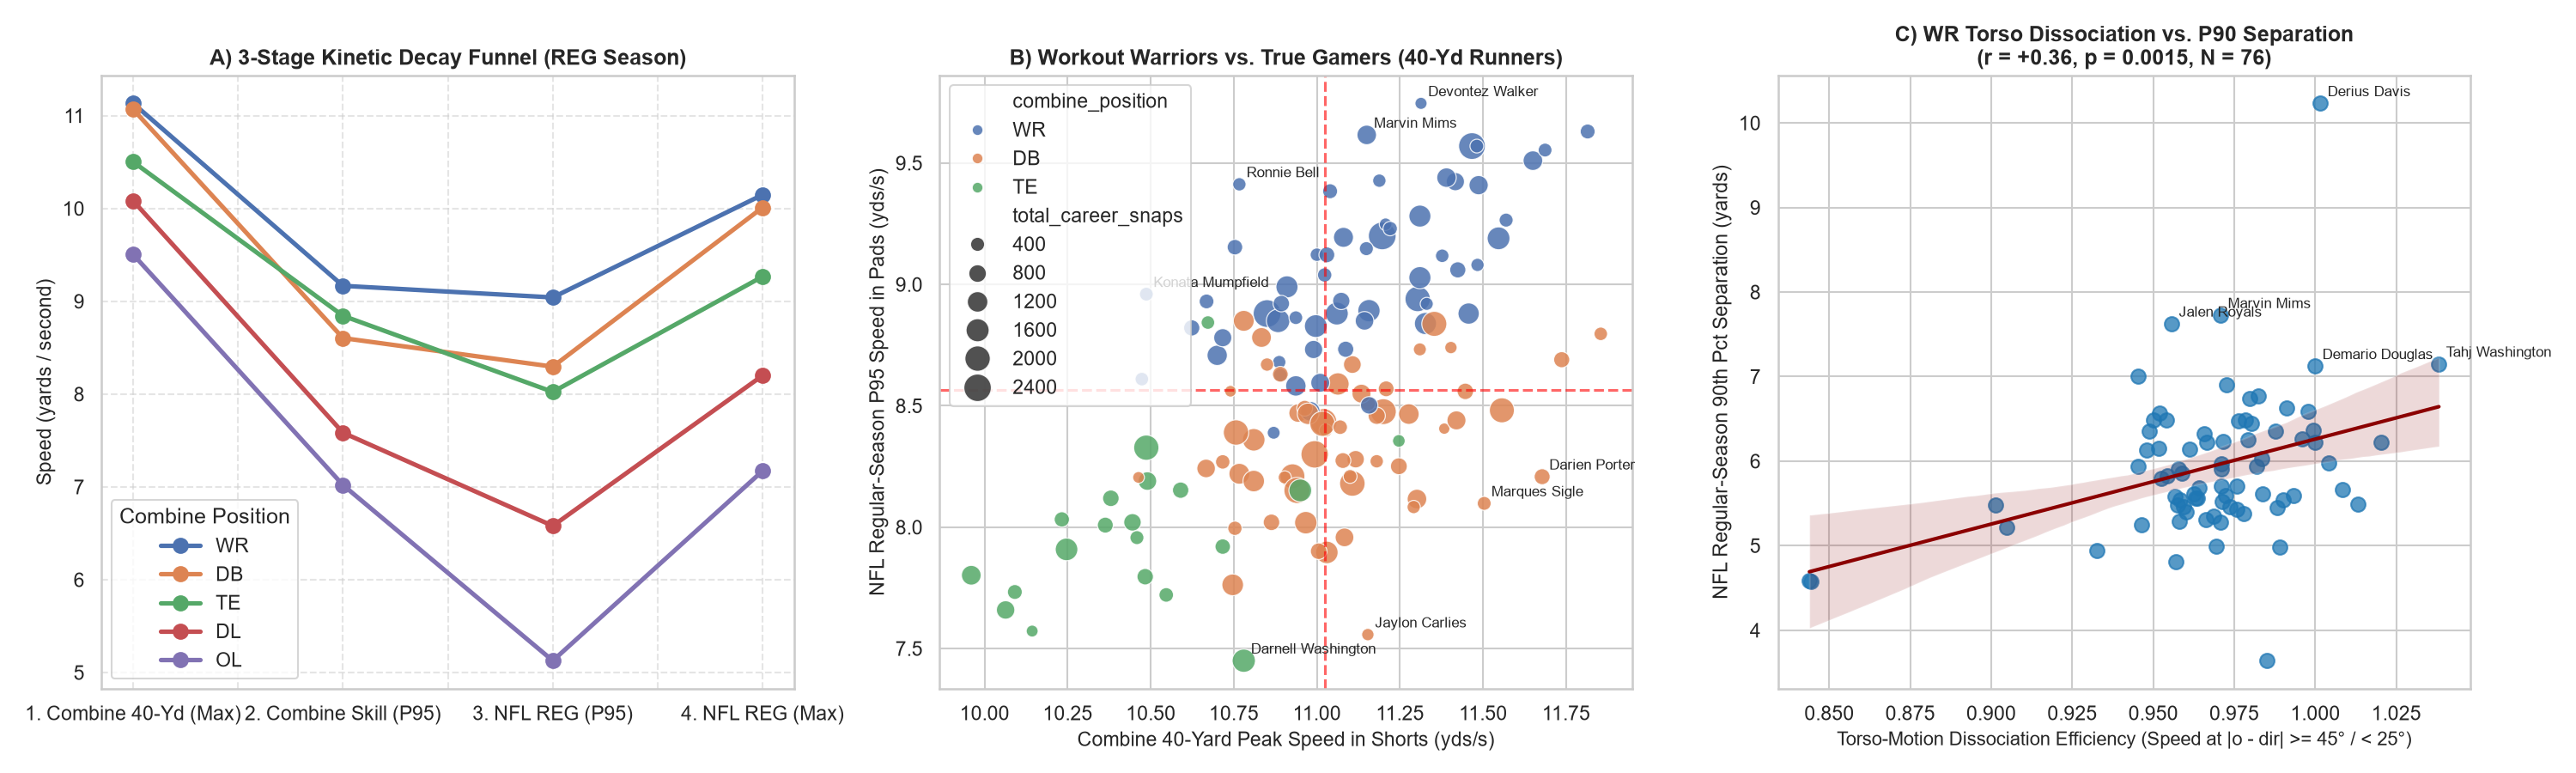

In [6]:
# ==============================================================================
# MODÜL 5: GÖRSELLEŞTİRME LABORATUVARI (FUNNEL, QUADRANT & TORSO DISSOCIATION)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

stage_plot_df = (
    reg_active.groupby('combine_position')[['forty_vmax', 's2_v95', 'nfl_v95', 'nfl_vmax']]
    .mean()
    .loc[['WR', 'DB', 'TE', 'DL', 'OL']]
)
stage_plot_df.columns = ['1. Combine 40-Yd (Max)', '2. Combine Skill (P95)', '3. NFL REG (P95)', '4. NFL REG (Max)']
stage_plot_df.T.plot(kind='line', marker='o', linewidth=2.5, markersize=8, ax=axes[0])
axes[0].set_title('A) 3-Stage Kinetic Decay Funnel (REG Season)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Speed (yards / second)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Combine Position', frameon=True)

skill_40 = reg_active[
    reg_active['combine_position'].isin(['WR', 'DB', 'TE']) &
    reg_active['forty_vmax'].notna() &
    (reg_active['total_career_snaps'] >= 150)
].copy()
x_med = skill_40['forty_vmax'].median()
y_med = skill_40['nfl_v95'].median()

sns.scatterplot(
    data=skill_40,
    x='forty_vmax',
    y='nfl_v95',
    hue='combine_position',
    size='total_career_snaps',
    sizes=(40, 240),
    alpha=0.85,
    ax=axes[1]
)
axes[1].axvline(x_med, color='red', linestyle='--', alpha=0.6)
axes[1].axhline(y_med, color='red', linestyle='--', alpha=0.6)
axes[1].set_title('B) Workout Warriors vs. True Gamers (40-Yd Runners)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Combine 40-Yard Peak Speed in Shorts (yds/s)', fontsize=11)
axes[1].set_ylabel('NFL Regular-Season P95 Speed in Pads (yds/s)', fontsize=11)

top_gems = skill_40.sort_values('KTR_Track_Speed', ascending=False).head(4)
top_warriors = skill_40.sort_values('KTR_Track_Speed', ascending=True).head(4)
for _, row in pd.concat([top_gems, top_warriors]).iterrows():
    axes[1].annotate(
        row['display_name'],
        (row['forty_vmax'], row['nfl_v95']),
        xytext=(4, 4), textcoords='offset points', fontsize=8
    )

wr_sub = reg_active[(reg_active['combine_position'] == 'WR') & reg_active['Torso_Dissoc_Efficiency'].notna() & reg_active['p90_separation'].notna()].copy()
sns.regplot(
    data=wr_sub,
    x='Torso_Dissoc_Efficiency',
    y='p90_separation',
    scatter_kws={'alpha': 0.75, 's': 65, 'color': '#1f77b4'},
    line_kws={'color': 'darkred', 'linewidth': 2},
    ax=axes[2]
)
r_val, p_val = stats.pearsonr(wr_sub['Torso_Dissoc_Efficiency'], wr_sub['p90_separation'])
axes[2].set_title(f'C) WR Torso Dissociation vs. P90 Separation\n(r = +{r_val:.2f}, p = {p_val:.4f}, N = {len(wr_sub)})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Torso-Motion Dissociation Efficiency (Speed at |o - dir| >= 45° / < 25°)', fontsize=10.5)
axes[2].set_ylabel('NFL Regular-Season 90th Pct Separation (yards)', fontsize=11)

for _, row in wr_sub.sort_values('p90_separation', ascending=False).head(5).iterrows():
    axes[2].annotate(row['display_name'], (row['Torso_Dissoc_Efficiency'], row['p90_separation']), xytext=(4, 4), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'ktr_funnel_and_quadrant.png', dpi=150)
plt.show()

cols_show = ['display_name', 'combine_position', 'draft_year', 'draft_round', 'forty', 'forty_vmax', 's2_v95', 'nfl_v95', 'KTR_Track_Speed', 'KTR_Skill_Speed', 'Torso_Dissoc_Efficiency', 'total_career_snaps']
print('\n=== EN YÜKSEK KTR_TRACK_SPEED (TRUE GAMERS / HIDDEN GEMS - 40-YD RUNNERS, >=150 SNAPS) ===')
display(skill_40.sort_values('KTR_Track_Speed', ascending=False)[cols_show].head(10))

print('\n=== EN DÜŞÜK KTR_TRACK_SPEED (WORKOUT WARRIORS / PAD-SPEED DROP-OFF - 40-YD RUNNERS, >=150 SNAPS) ===')
display(skill_40.sort_values('KTR_Track_Speed', ascending=True)[cols_show].head(10))

=== 1. SPLIT-HALF STABILITY (TEK HAFTALAR vs. ÇİFT HAFTALAR TUTARLILIK TESTİ) ===
                              Metric  N_Players  Odd_vs_Even_Week_r  Spearman_Brown_Reliability   p_value
      KTR_Track_Speed (40-Yd -> NFL)        287               0.939                       0.969 4.05e-134
KTR_Skill_Speed (Skill Drill -> NFL)        342               0.906                       0.951 7.88e-129
KTR_Skill_Accel (Skill Accel -> NFL)        342               0.935                       0.966 2.87e-155
       Torso_Dissoc_Efficiency (DEI)        342               0.803                       0.891  1.50e-78
    In-Game 95th Pct Speed (nfl_v95)        342               0.968                       0.984 1.19e-206

=== 2. MAN COVERAGE vs. ZONE COVERAGE BAĞLAMSAL KONTROLÜ (WR SEPARATION) ===
Coverage_Type               Predictor  N_WRs  r_P90_Separation  p_val_P90  r_Avg_Separation  p_val_Avg
 MAN_COVERAGE                   forty     67            -0.145     0.2408            -0.128     0.302

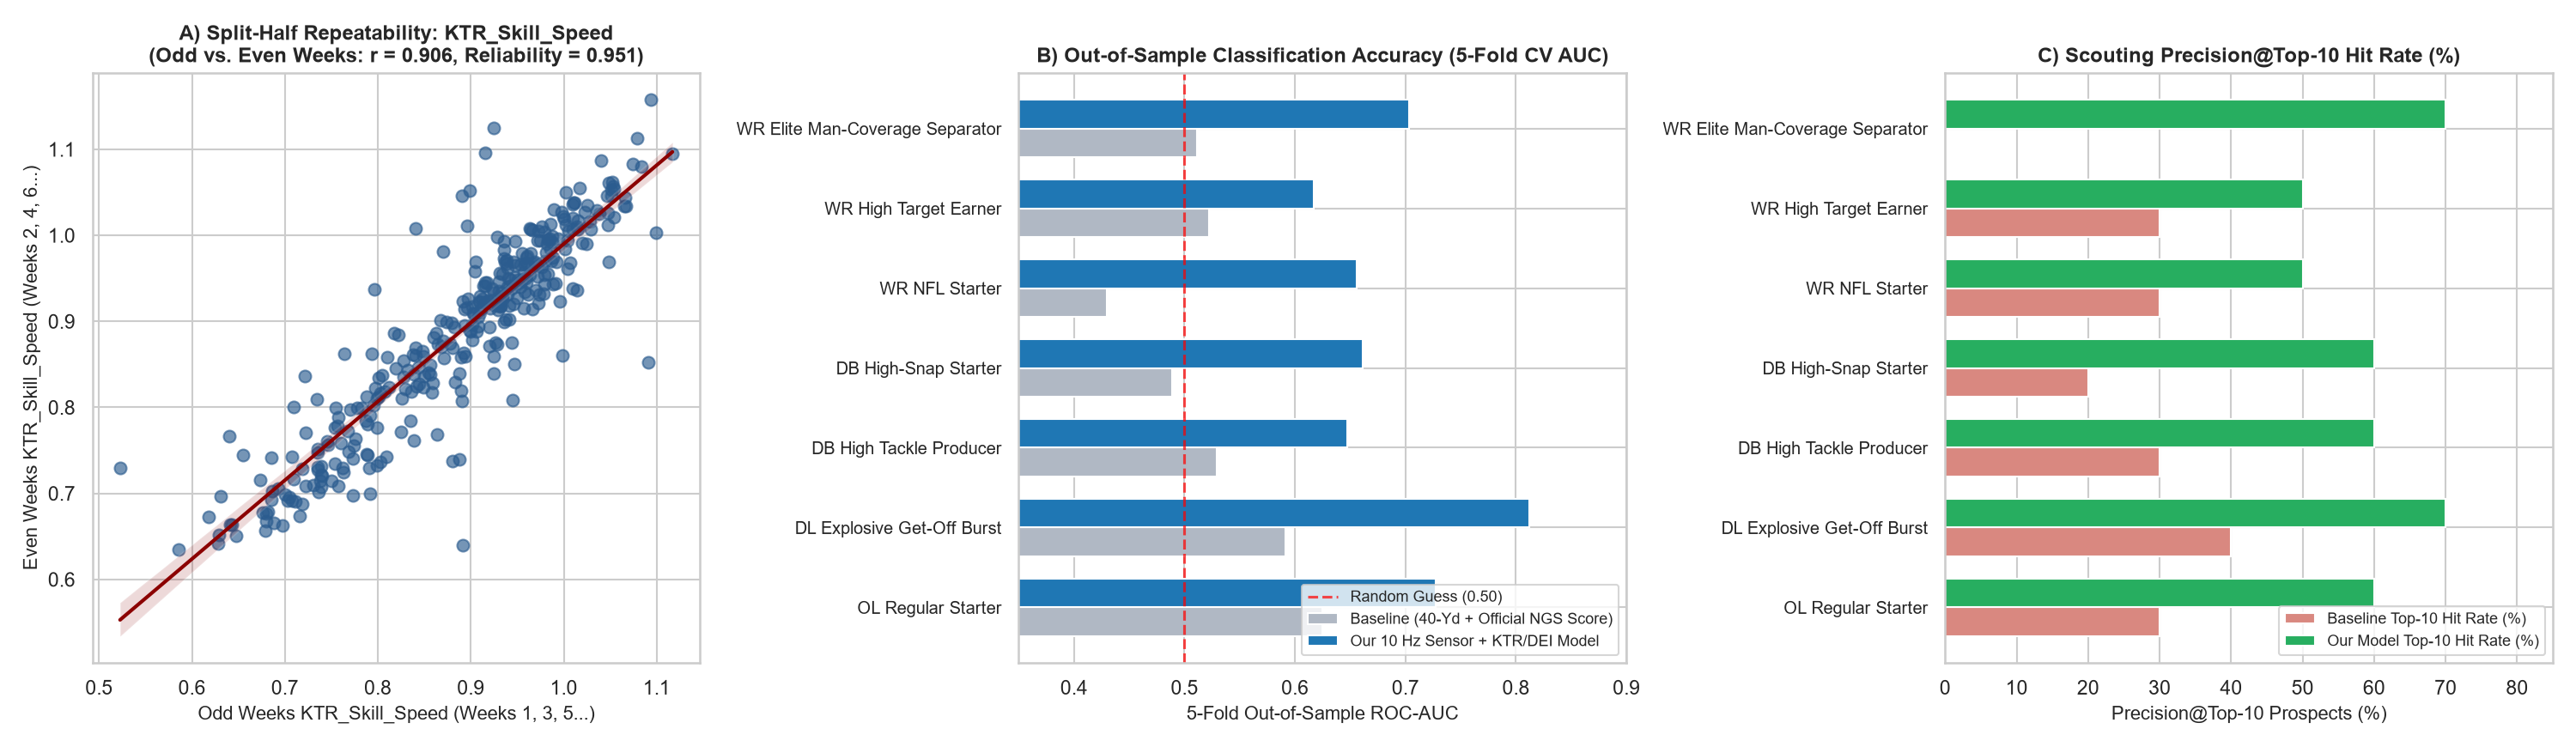

In [7]:
# ==============================================================================
# MODÜL 6: DOĞRULAMA (VALIDATION), KARARLILIK (SPLIT-HALF RELIABILITY),
#          MAN vs. ZONE KONTROLÜ VE OUT-OF-SAMPLE BENCHMARK LABORATUVARI
# ==============================================================================
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_predict
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, roc_curve

print('=== 1. SPLIT-HALF STABILITY (TEK HAFTALAR vs. ÇİFT HAFTALAR TUTARLILIK TESTİ) ===')
odd_plays = nfl_reg_plays_df[nfl_reg_plays_df['week'] % 2 == 1]
even_plays = nfl_reg_plays_df[nfl_reg_plays_df['week'] % 2 == 0]

def compute_half_season_metrics(df_half, suffix):
    g = df_half.groupby('nfl_id').agg(
        n_plays=('play_id', 'count'),
        v95=('play_max_speed', lambda x: np.nanpercentile(x, 95)),
        a95=('play_max_accel', lambda x: np.nanpercentile(x, 95)),
        v95_high_d=('max_speed_high_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 3 else np.nan),
        v95_low_d=('max_speed_low_dissoc', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) >= 3 else np.nan),
    ).reset_index()
    g = g[g['n_plays'] >= 12].copy()
    g[f'dei_{suffix}'] = g['v95_high_d'] / g['v95_low_d']
    return g[['nfl_id', 'v95', 'a95', f'dei_{suffix}']].rename(columns={'v95': f'v95_{suffix}', 'a95': f'a95_{suffix}'})

odd_m = compute_half_season_metrics(odd_plays, 'odd')
even_m = compute_half_season_metrics(even_plays, 'even')
split_df = reg_active[['nfl_id', 'combine_position', 'forty_vmax', 's2_v95', 's2_a95']].merge(odd_m, on='nfl_id').merge(even_m, on='nfl_id')

split_df['KTR_Track_odd'] = split_df['v95_odd'] / split_df['forty_vmax']
split_df['KTR_Track_even'] = split_df['v95_even'] / split_df['forty_vmax']
split_df['KTR_Skill_odd'] = split_df['v95_odd'] / split_df['s2_v95']
split_df['KTR_Skill_even'] = split_df['v95_even'] / split_df['s2_v95']
split_df['KTR_Accel_odd'] = split_df['a95_odd'] / split_df['s2_a95']
split_df['KTR_Accel_even'] = split_df['a95_even'] / split_df['s2_a95']

stab_rows = []
for metric_name, c_odd, c_even in [
    ('KTR_Track_Speed (40-Yd -> NFL)', 'KTR_Track_odd', 'KTR_Track_even'),
    ('KTR_Skill_Speed (Skill Drill -> NFL)', 'KTR_Skill_odd', 'KTR_Skill_even'),
    ('KTR_Skill_Accel (Skill Accel -> NFL)', 'KTR_Accel_odd', 'KTR_Accel_even'),
    ('Torso_Dissoc_Efficiency (DEI)', 'dei_odd', 'dei_even'),
    ('In-Game 95th Pct Speed (nfl_v95)', 'v95_odd', 'v95_even'),
]:
    v = split_df[[c_odd, c_even]].dropna()
    r, p = stats.pearsonr(v[c_odd], v[c_even])
    r_sb = (2.0 * r) / (1.0 + r)
    stab_rows.append({
        'Metric': metric_name,
        'N_Players': len(v),
        'Odd_vs_Even_Week_r': round(r, 3),
        'Spearman_Brown_Reliability': round(r_sb, 3),
        'p_value': f'{p:.2e}'
    })
stab_summary_df = pd.DataFrame(stab_rows)
display(stab_summary_df)

print('\n=== 2. MAN COVERAGE vs. ZONE COVERAGE BAĞLAMSAL KONTROLÜ (WR SEPARATION) ===')
wr_cov_rows = []
wr_sep_plays = nfl_reg_plays_df[(nfl_reg_plays_df['combine_position'] == 'WR') & nfl_reg_plays_df['separation'].notna()]
for cov_type in ['MAN_COVERAGE', 'ZONE_COVERAGE']:
    sub_cov = wr_sep_plays[wr_sep_plays['team_coverage_man_zone'] == cov_type]
    cov_agg = sub_cov.groupby('nfl_id').agg(
        n_routes=('play_id', 'count'),
        avg_sep=('separation', 'mean'),
        p90_sep=('separation', lambda x: np.nanpercentile(x, 90)),
    ).reset_index()
    cov_agg = cov_agg[cov_agg['n_routes'] >= 8].merge(
        reg_active[['nfl_id', 'forty', 'ngs_athleticism_score', 'Torso_Dissoc_Efficiency']], on='nfl_id'
    )
    for pred_col in ['forty', 'ngs_athleticism_score', 'Torso_Dissoc_Efficiency']:
        v = cov_agg[[pred_col, 'p90_sep', 'avg_sep']].dropna()
        r90, p90 = stats.pearsonr(v[pred_col], v['p90_sep'])
        ravg, pavg = stats.pearsonr(v[pred_col], v['avg_sep'])
        wr_cov_rows.append({
            'Coverage_Type': cov_type,
            'Predictor': pred_col,
            'N_WRs': len(v),
            'r_P90_Separation': round(r90, 3),
            'p_val_P90': round(p90, 4),
            'r_Avg_Separation': round(ravg, 3),
            'p_val_Avg': round(pavg, 4),
        })
display(pd.DataFrame(wr_cov_rows))

man_wr_df = wr_sep_plays[wr_sep_plays['team_coverage_man_zone'] == 'MAN_COVERAGE'].groupby('nfl_id').agg(
    n_man=('play_id', 'count'),
    man_p90_sep=('separation', lambda x: np.nanpercentile(x, 90))
).reset_index()
reg_active_val = reg_active.merge(man_wr_df[man_wr_df['n_man'] >= 8][['nfl_id', 'man_p90_sep']], on='nfl_id', how='left')

print('\n=== 3. 5-FOLD CROSS-VALIDATION BENCHMARK: 40-YD + NGS SKORU vs. BİZİM SENSÖR/KTR MODELİMİZ ===')
benchmark_tasks = [
    ('WR Elite Man-Coverage Separator (Top-35%)', ['WR'], 'man_p90_sep', ['forty', 'ngs_athleticism_score'], ['Torso_Dissoc_Efficiency', 'KTR_Skill_Speed'], 'high'),
    ('WR High Target Earner (Top-35% Target Rate)', ['WR'], 'target_rate', ['forty', 'ngs_athleticism_score'], ['s2_centripetal95', 's2_power95', 'Torso_Dissoc_Efficiency'], 'high'),
    ('WR NFL Starter (Top-35% Starter Ratio)', ['WR'], 'starter_ratio', ['forty', 'ngs_athleticism_score'], ['s2_power95', 's2_centripetal95', 'Torso_Dissoc_Efficiency'], 'high'),
    ('DB High-Snap Starter (Top-35% Career Snaps)', ['DB'], 'total_career_snaps', ['forty', 'ngs_athleticism_score'], ['forty_amax', 's2_centripetal95', 'KTR_Skill_Accel'], 'high'),
    ('DB High Tackle Producer (Top-35% Tackles)', ['DB'], 'total_tackles', ['forty', 'ngs_athleticism_score'], ['forty_amax', 'KTR_Skill_Accel'], 'high'),
    ('DL Explosive Get-Off Burst (Fastest 35%)', ['DL'], 'avg_get_off', ['ngs_athleticism_score'], ['s2_power95', 's2_v95', 'KTR_Skill_Accel'], 'low'),
    ('OL Regular Starter (Top-35% Starter Ratio)', ['OL'], 'starter_ratio', ['forty', 'ngs_athleticism_score'], ['Torso_Dissoc_Efficiency', 's2_a95'], 'high'),
]

cv_results = []
for task_name, pos_list, targ_col, base_cols, sens_cols, direction in benchmark_tasks:
    sub = reg_active_val[reg_active_val['combine_position'].isin(pos_list) & reg_active_val[targ_col].notna()].copy()
    thresh = np.nanpercentile(sub[targ_col], 65 if direction == 'high' else 35)
    y = (sub[targ_col] >= thresh).astype(int).values if direction == 'high' else (sub[targ_col] <= thresh).astype(int).values
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    m_base = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    m_sens = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    
    p_base = cross_val_predict(m_base, sub[base_cols], y, cv=skf, method='predict_proba')[:, 1]
    p_sens = cross_val_predict(m_sens, sub[sens_cols], y, cv=skf, method='predict_proba')[:, 1]
    
    auc_b = roc_auc_score(y, p_base)
    auc_s = roc_auc_score(y, p_sens)
    top10_b = y[np.argsort(p_base)[::-1][:10]].mean() * 100.0
    top10_s = y[np.argsort(p_sens)[::-1][:10]].mean() * 100.0
    
    cv_results.append({
        'Evaluation_Task': task_name,
        'N': len(sub),
        'Baseline_AUC': round(auc_b, 3),
        'Our_Sensor_AUC': round(auc_s, 3),
        'AUC_Gain': round(auc_s - auc_b, 3),
        'Base_Top10_Hit_%': round(top10_b, 0),
        'Our_Top10_Hit_%': round(top10_s, 0),
    })

cv_bench_df = pd.DataFrame(cv_results)
display(cv_bench_df)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sns.regplot(
    data=split_df,
    x='KTR_Skill_odd',
    y='KTR_Skill_even',
    scatter_kws={'alpha': 0.65, 's': 45, 'color': '#2b5c8f'},
    line_kws={'color': 'darkred', 'linewidth': 2},
    ax=axes[0]
)
r_split = stab_summary_df.loc[stab_summary_df['Metric'].str.startswith('KTR_Skill_Speed'), 'Odd_vs_Even_Week_r'].values[0]
rsb_split = stab_summary_df.loc[stab_summary_df['Metric'].str.startswith('KTR_Skill_Speed'), 'Spearman_Brown_Reliability'].values[0]
axes[0].set_title(f'A) Split-Half Repeatability: KTR_Skill_Speed\n(Odd vs. Even Weeks: r = {r_split:.3f}, Reliability = {rsb_split:.3f})', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Odd Weeks KTR_Skill_Speed (Weeks 1, 3, 5...)', fontsize=10.5)
axes[0].set_ylabel('Even Weeks KTR_Skill_Speed (Weeks 2, 4, 6...)', fontsize=10.5)

y_pos = np.arange(len(cv_bench_df))
height = 0.36
axes[1].barh(y_pos + height/2, cv_bench_df['Baseline_AUC'], height, label='Baseline (40-Yd + Official NGS Score)', color='#b0b8c4')
axes[1].barh(y_pos - height/2, cv_bench_df['Our_Sensor_AUC'], height, label='Our 10 Hz Sensor + KTR/DEI Model', color='#1f77b4')
axes[1].axvline(0.50, color='red', linestyle='--', alpha=0.7, label='Random Guess (0.50)')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([t.split(' (')[0] for t in cv_bench_df['Evaluation_Task']], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlim(0.35, 0.90)
axes[1].set_xlabel('5-Fold Out-of-Sample ROC-AUC', fontsize=10.5)
axes[1].set_title('B) Out-of-Sample Classification Accuracy (5-Fold CV AUC)', fontsize=11.5, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=8.5, frameon=True)

axes[2].barh(y_pos + height/2, cv_bench_df['Base_Top10_Hit_%'], height, label='Baseline Top-10 Hit Rate (%)', color='#d98880')
axes[2].barh(y_pos - height/2, cv_bench_df['Our_Top10_Hit_%'], height, label='Our Model Top-10 Hit Rate (%)', color='#27ae60')
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels([t.split(' (')[0] for t in cv_bench_df['Evaluation_Task']], fontsize=9.5)
axes[2].invert_yaxis()
axes[2].set_xlim(0, 85)
axes[2].set_xlabel('Precision@Top-10 Prospects (%)', fontsize=10.5)
axes[2].set_title('C) Scouting Precision@Top-10 Hit Rate (%)', fontsize=11.5, fontweight='bold')
axes[2].legend(loc='lower right', fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'validation_benchmark_suite.png', dpi=150)
plt.show()

=== 1. SAF COMBINE WR MİKRO-ÖZELLİKLERİ -> NFL HEDEFLERİ TEKİL KORELASYONLAR ===
                        Pre_Draft_Combine_Micro_Feature                   Future_NFL_Target  N_WRs  Pearson_r  p_value
         hb_cut_speed (Keskin Dönüş Hızı, omega>=60°/s)                WR İlk 11 Olma Oranı     76      0.330   0.0036
        hb_cut_speed_retention (Dönüş Hız Koruma Oranı)                WR İlk 11 Olma Oranı     76      0.310   0.0065
s2_centripetal95 (Combine Merkezcil Dönüş Gücü v*omega)             WR Pas Hedeflenme Oranı     76      0.322   0.0046
     hb_centripetal95 (Hard-Break Merkezcil Dönüş Gücü)             WR Pas Hedeflenme Oranı     76      0.268   0.0193
        gaunt_vmean (Gauntlet Drill Ortalama Akış Hızı) WR Ortalama YAC (Yards After Catch)     75      0.260   0.0244
                  forty_vmax (40-Yard Sensör Tepe Hızı) NFL Gövde Ayrışma Verimliliği (DEI)     68      0.407   0.0006
             deep_v95 (Derin Rota / Over-Shoulder Hızı) NFL Gövde Ayrışma Verimliliği 

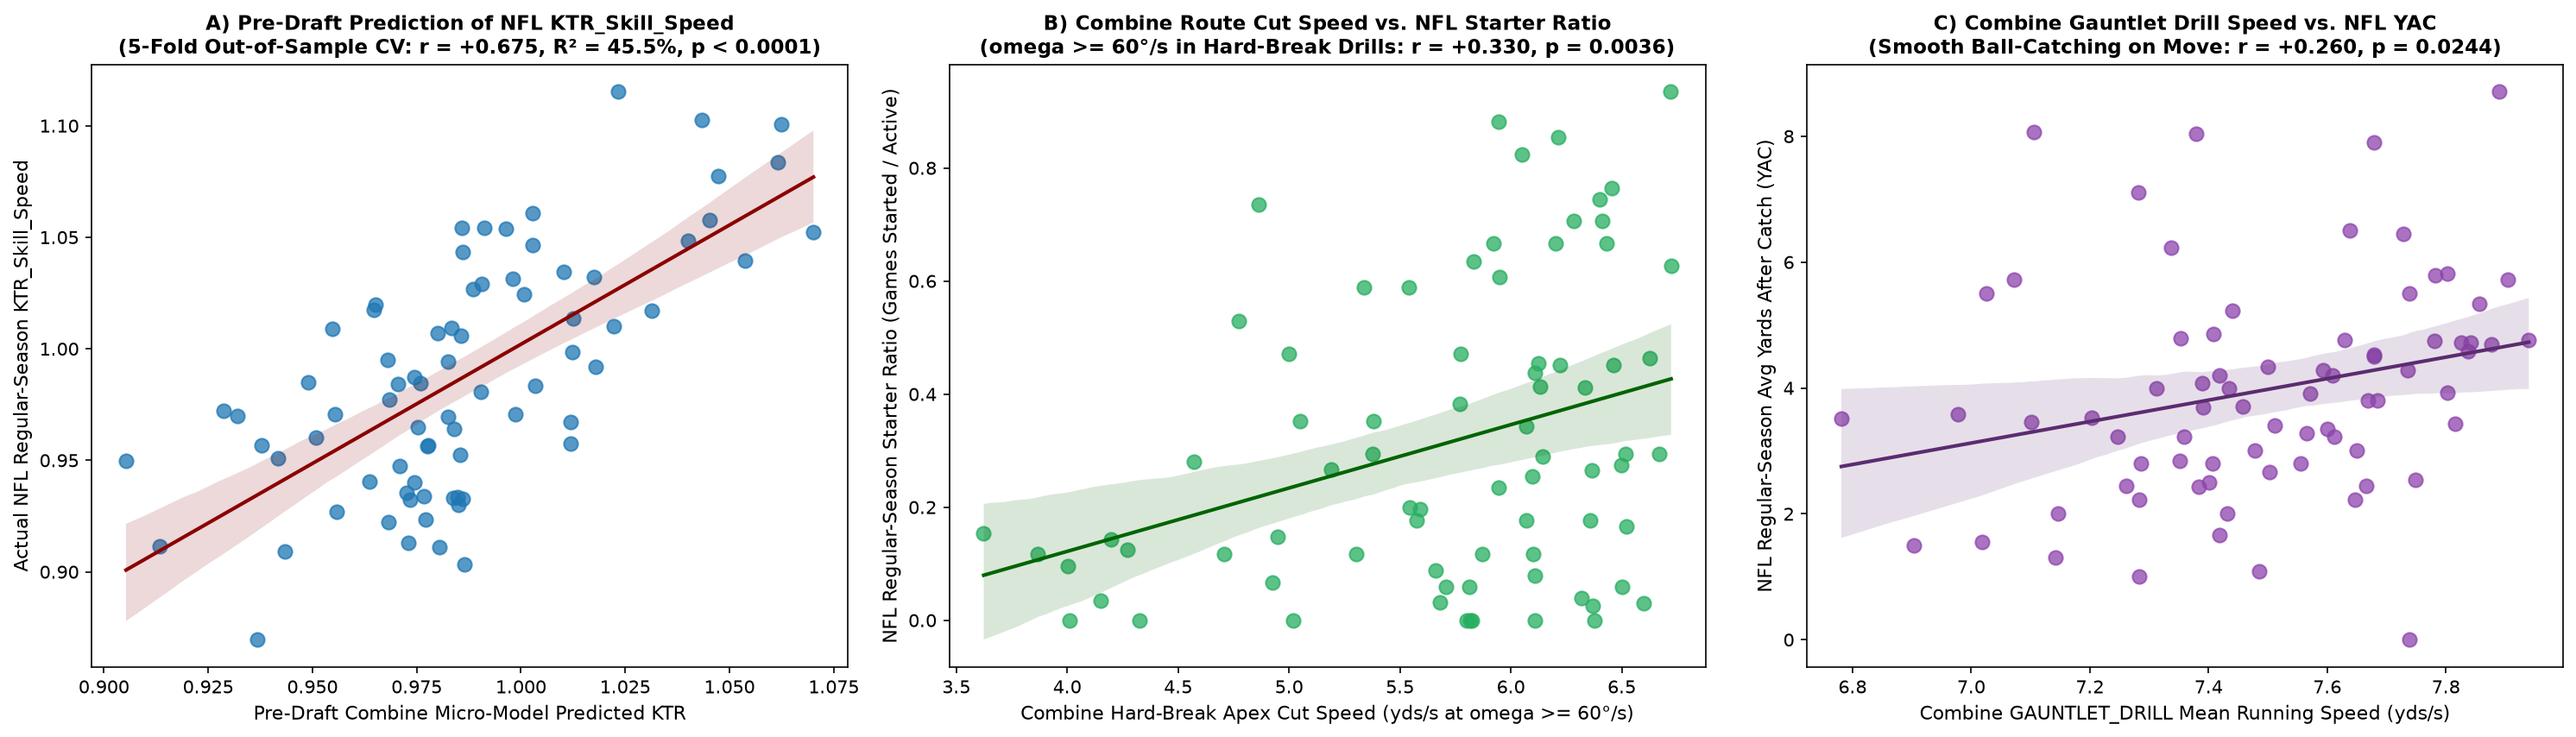

In [8]:
# ==============================================================================
# MODÜL 7 (ADIM 1): WR PRE-DRAFT MİKRO-ÖZELLİK TAHMİN MODELİ
# (Sadece Combine WR Drillerinden Gelecekteki NFL KTR, DEI ve Başarı Tahmini)
# ==============================================================================
comb_wr = pd.read_parquet(CACHE_DIR / 'by_position' / 'combine_tracking_WR.parquet')
wr_reg_master = reg_active_val[reg_active_val['combine_position'] == 'WR'].copy()

HARD_BREAK_ROUTES = {
    'CURL_ROUTE_RIGHT', 'COMEBACK_ROUTE_RIGHT', 'DAGGER_ROUTE_LEFT',
    'SPEED_OUT_ROUTE_LEFT', 'POST_CORNER_ROUTE_RIGHT', 'POST_CORNER_ROUTE_LEFT',
    'SLANT_ROUTE_LEFT', 'SLOT_STRIKE_ROUTE_LEFT'
}
DEEP_TRACKING_ROUTES = {
    'GO_ROUTE_RIGHT', 'SLOT_SAIL_ROUTE_RIGHT', 'RED_ZONE_FADE_RIGHT',
    'OVER_SHOULDER_ADJUST', 'CIRCUS_ROUTE_LEFT'
}

gaunt_run = comb_wr[(comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['s'] >= 3.0)]
gaunt_feats = gaunt_run.groupby('nfl_id').agg(
    gaunt_vmax=('s', 'max'),
    gaunt_vmean=('s', 'mean'),
    gaunt_a90=('a', lambda x: np.nanpercentile(x, 90)),
    gaunt_centripetal90=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 90) if len(x.dropna()) else np.nan),
).reset_index()

hb_run = comb_wr[comb_wr['drill_name'].isin(HARD_BREAK_ROUTES) & (comb_wr['s'] >= 2.0)]
hb_feats = hb_run.groupby('nfl_id').agg(
    hb_v95=('s', lambda x: np.nanpercentile(x, 95)),
    hb_a95=('a', lambda x: np.nanpercentile(x, 95)),
    hb_brake_p5=('signed_accel', lambda x: np.nanpercentile(x.dropna(), 5) if len(x.dropna()) else np.nan),
    hb_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
    hb_power95=('mechanical_power_proxy', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
    hb_cut_speed=('s', lambda x: np.nanpercentile(x[hb_run.loc[x.index, 'omega_deg_s'] >= 60.0], 85) if (hb_run.loc[x.index, 'omega_deg_s'] >= 60.0).any() else np.nan),
).reset_index()
hb_feats['hb_cut_speed_retention'] = hb_feats['hb_cut_speed'] / hb_feats['hb_v95']

deep_run = comb_wr[comb_wr['drill_name'].isin(DEEP_TRACKING_ROUTES) & (comb_wr['s'] >= 2.5)]
deep_feats = deep_run.groupby('nfl_id').agg(
    deep_v95=('s', lambda x: np.nanpercentile(x, 95)),
    deep_a95=('a', lambda x: np.nanpercentile(x, 95)),
    deep_centripetal95=('centripetal_accel', lambda x: np.nanpercentile(x.dropna(), 95) if len(x.dropna()) else np.nan),
).reset_index()

f40_run = comb_wr[(comb_wr['drill_type'] == 'FORTY_YARD_DASH') & (comb_wr['s'] >= 1.0)].copy()
f40_run['frame_idx'] = f40_run.groupby(['nfl_id', 'event_id', 'attempt']).cumcount()
f40_feats = f40_run.groupby('nfl_id').agg(
    f40_early_v15=('s', lambda x: x[f40_run.loc[x.index, 'frame_idx'] <= 15].max() if (f40_run.loc[x.index, 'frame_idx'] <= 15).any() else np.nan),
    f40_late_vmax=('s', 'max'),
).reset_index()
f40_feats['f40_early_to_peak_ratio'] = f40_feats['f40_early_v15'] / f40_feats['f40_late_vmax']

wr_micro_df = (
    wr_reg_master
    .merge(gaunt_feats, on='nfl_id', how='left')
    .merge(hb_feats, on='nfl_id', how='left')
    .merge(deep_feats, on='nfl_id', how='left')
    .merge(f40_feats, on='nfl_id', how='left')
)
wr_micro_df['comb_hb_to_40_speed'] = wr_micro_df['hb_v95'] / wr_micro_df['forty_vmax']
wr_micro_df['comb_deep_to_40_speed'] = wr_micro_df['deep_v95'] / wr_micro_df['forty_vmax']
wr_micro_df.to_parquet(CACHE_DIR / 'wr_predraft_micro_master.parquet', index=False)

print('=== 1. SAF COMBINE WR MİKRO-ÖZELLİKLERİ -> NFL HEDEFLERİ TEKİL KORELASYONLAR ===')
single_signals = [
    ('hb_cut_speed (Keskin Dönüş Hızı, omega>=60°/s)', 'starter_ratio', 'WR İlk 11 Olma Oranı'),
    ('hb_cut_speed_retention (Dönüş Hız Koruma Oranı)', 'starter_ratio', 'WR İlk 11 Olma Oranı'),
    ('s2_centripetal95 (Combine Merkezcil Dönüş Gücü v*omega)', 'target_rate', 'WR Pas Hedeflenme Oranı'),
    ('hb_centripetal95 (Hard-Break Merkezcil Dönüş Gücü)', 'target_rate', 'WR Pas Hedeflenme Oranı'),
    ('gaunt_vmean (Gauntlet Drill Ortalama Akış Hızı)', 'avg_yac', 'WR Ortalama YAC (Yards After Catch)'),
    ('forty_vmax (40-Yard Sensör Tepe Hızı)', 'Torso_Dissoc_Efficiency', 'NFL Gövde Ayrışma Verimliliği (DEI)'),
    ('deep_v95 (Derin Rota / Over-Shoulder Hızı)', 'Torso_Dissoc_Efficiency', 'NFL Gövde Ayrışma Verimliliği (DEI)'),
    ('f40_early_to_peak_ratio (40-Yd İkinci Vites Rezervi)', 'man_p90_sep', 'NFL Man Coverage P90 Separation'),
    ('comb_hb_to_40_speed (Combine Rota / 40-Yd Hız Oranı)', 'KTR_Skill_Speed', 'NFL KTR_Skill_Speed Aktarımı'),
]
sig_table = []
for col_label, targ_col, targ_desc in single_signals:
    col_name = col_label.split(' ')[0]
    v = wr_micro_df[[col_name, targ_col]].dropna()
    r, p = stats.pearsonr(v[col_name], v[targ_col])
    sig_table.append({
        'Pre_Draft_Combine_Micro_Feature': col_label,
        'Future_NFL_Target': targ_desc,
        'N_WRs': len(v),
        'Pearson_r': round(r, 3),
        'p_value': round(p, 4)
    })
display(pd.DataFrame(sig_table))

print('\n=== 2. ÇOK DEĞİŞKENLİ PRE-DRAFT WR MODELİ (5-FOLD OUT-OF-SAMPLE CV): KRONOMETRE+NGS vs. COMBINE MİKRO-MODEL ===')
predraft_models = [
    ('Future NFL KTR_Skill_Speed', 'KTR_Skill_Speed', ['forty_vmax', 'hb_v95', 'deep_v95', 'comb_hb_to_40_speed', 'comb_deep_to_40_speed']),
    ('Future NFL In-Game Speed (nfl_v95)', 'nfl_v95', ['forty_vmax', 'hb_cut_speed', 'deep_v95', 'comb_hb_to_40_speed']),
    ('Future NFL Torso_Dissoc_Efficiency (DEI)', 'Torso_Dissoc_Efficiency', ['forty_vmax', 'deep_v95', 'f40_early_to_peak_ratio', 'hb_cut_speed_retention']),
    ('Future NFL Starter Ratio', 'starter_ratio', ['hb_cut_speed', 'hb_cut_speed_retention', 's2_power95', 's2_centripetal95', 'f40_early_v15']),
    ('Future NFL Man-Coverage P90 Separation', 'man_p90_sep', ['f40_early_to_peak_ratio', 'forty_vmax', 'deep_v95']),
]
pm_rows = []
cv_preds_store = {}
for label, targ, feats in predraft_models:
    sub = wr_micro_df[['nfl_id', 'display_name', 'forty', 'ngs_athleticism_score', targ] + feats].dropna(subset=[targ]).copy()
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    m_base = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0))
    m_micro = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0))
    
    pb = cross_val_predict(m_base, sub[['forty', 'ngs_athleticism_score']], sub[targ], cv=kf)
    pm = cross_val_predict(m_micro, sub[feats], sub[targ], cv=kf)
    cv_preds_store[targ] = (sub, pb, pm)
    
    rb, p_b = stats.pearsonr(sub[targ], pb)
    rm, p_m = stats.pearsonr(sub[targ], pm)
    pm_rows.append({
        'Predicted_NFL_Outcome': label,
        'N_WRs': len(sub),
        'Base_CV_r (40yd+NGS)': round(rb, 3),
        'Base_CV_R2_%': round((rb**2)*100 if rb > 0 else 0.0, 1),
        'PreDraft_Micro_CV_r': round(rm, 3),
        'PreDraft_Micro_CV_R2_%': round((rm**2)*100, 1),
        'Micro_p_val': round(p_m, 4),
    })
pm_df = pd.DataFrame(pm_rows)
display(pm_df)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sub_ktr, _, pm_ktr = cv_preds_store['KTR_Skill_Speed']
sns.regplot(x=pm_ktr, y=sub_ktr['KTR_Skill_Speed'], scatter_kws={'alpha': 0.75, 's': 60, 'color': '#1f77b4'}, line_kws={'color': 'darkred', 'linewidth': 2}, ax=axes[0])
r_k, p_k = stats.pearsonr(pm_ktr, sub_ktr['KTR_Skill_Speed'])
axes[0].set_title(f'A) Pre-Draft Prediction of NFL KTR_Skill_Speed\n(5-Fold Out-of-Sample CV: r = +{r_k:.3f}, R² = {r_k**2*100:.1f}%, p < 0.0001)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Pre-Draft Combine Micro-Model Predicted KTR', fontsize=10.5)
axes[0].set_ylabel('Actual NFL Regular-Season KTR_Skill_Speed', fontsize=10.5)

sns.regplot(data=wr_micro_df, x='hb_cut_speed', y='starter_ratio', scatter_kws={'alpha': 0.75, 's': 60, 'color': '#27ae60'}, line_kws={'color': 'darkgreen', 'linewidth': 2}, ax=axes[1])
r_st, p_st = stats.pearsonr(wr_micro_df[['hb_cut_speed', 'starter_ratio']].dropna()['hb_cut_speed'], wr_micro_df[['hb_cut_speed', 'starter_ratio']].dropna()['starter_ratio'])
axes[1].set_title(f'B) Combine Route Cut Speed vs. NFL Starter Ratio\n(omega >= 60°/s in Hard-Break Drills: r = +{r_st:.3f}, p = {p_st:.4f})', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Combine Hard-Break Apex Cut Speed (yds/s at omega >= 60°/s)', fontsize=10.5)
axes[1].set_ylabel('NFL Regular-Season Starter Ratio (Games Started / Active)', fontsize=10.5)

v_yac = wr_micro_df[['display_name', 'gaunt_vmean', 'avg_yac']].dropna()
sns.regplot(data=v_yac, x='gaunt_vmean', y='avg_yac', scatter_kws={'alpha': 0.75, 's': 60, 'color': '#8e44ad'}, line_kws={'color': '#5b2c6f', 'linewidth': 2}, ax=axes[2])
r_yc, p_yc = stats.pearsonr(v_yac['gaunt_vmean'], v_yac['avg_yac'])
axes[2].set_title(f'C) Combine Gauntlet Drill Speed vs. NFL YAC\n(Smooth Ball-Catching on Move: r = +{r_yc:.3f}, p = {p_yc:.4f})', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Combine GAUNTLET_DRILL Mean Running Speed (yds/s)', fontsize=10.5)
axes[2].set_ylabel('NFL Regular-Season Avg Yards After Catch (YAC)', fontsize=10.5)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_predraft_micro_model.png', dpi=150)
plt.show()

=== VAKA ANALİZİ (CASE STUDY): MARVIN MIMS (4.38s) vs. XAVIER LEGETTE (4.39s) ===
  display_name  draft_year  draft_round  forty  forty_vmax  gaunt_vmax  gaunt_vmean  nfl_v95  KTR_Track_Speed  KTR_Skill_Speed  Torso_Dissoc_Efficiency  p90_separation  man_p90_sep  total_career_snaps
   Marvin Mims        2023          2.0   4.38   11.150000    9.313333     7.889505    9.616         0.862422         1.009342                 0.970808        7.725683     5.835545                1059
Xavier Legette        2024          1.0   4.39   11.456667    8.890000     7.646535    8.880         0.775095         0.933165                 0.972350        5.591698     4.042496                1321


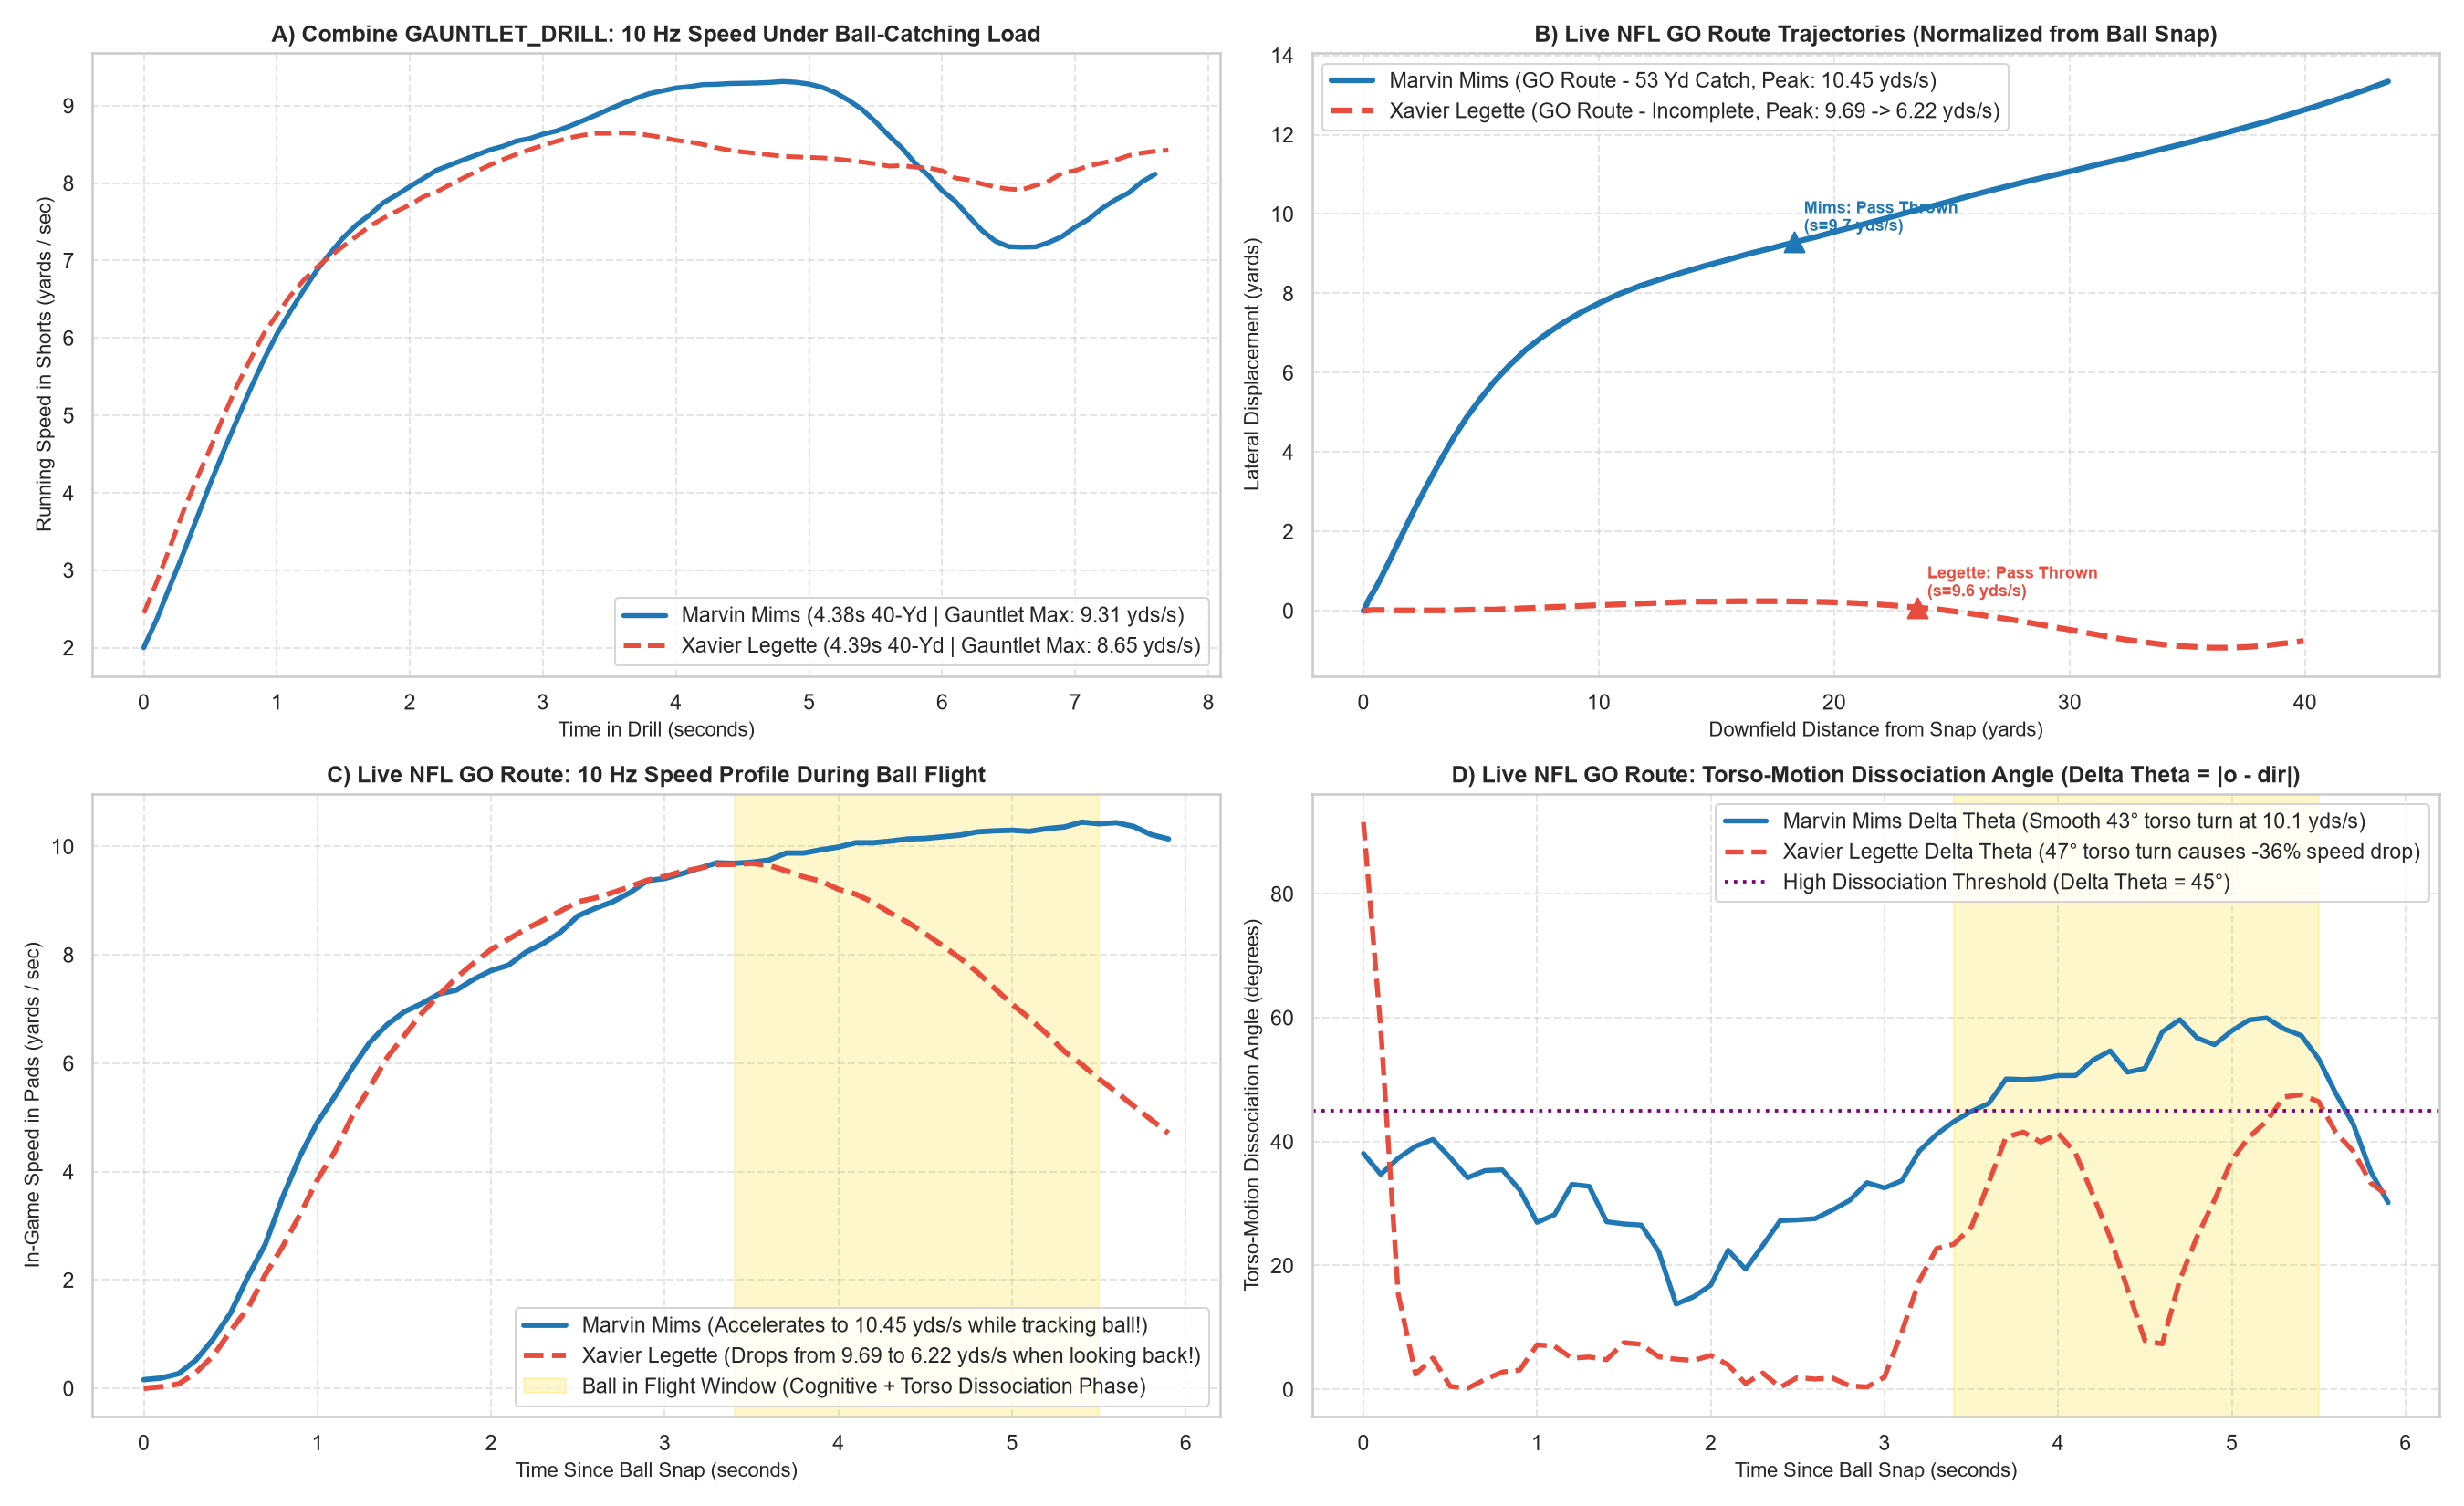

In [9]:
# ==============================================================================
# MODÜL 8 (ADIM 2): 10 Hz FRAME-BY-FRAME VAKA ANALİZİ (CASE STUDY)
# MARVIN MIMS (4.38s - True Gamer) vs. XAVIER LEGETTE (4.39s - Workout Warrior)
# ==============================================================================
case_nfl_path = CACHE_DIR / 'case_study_nfl_frames.parquet'
if not case_nfl_path.exists():
    case_query = f"""
        SELECT 
            TRY_CAST(game_id AS BIGINT) AS game_id,
            TRY_CAST(play_id AS INTEGER) AS play_id,
            TRY_CAST(nfl_id AS INTEGER) AS nfl_id,
            time,
            TRY_CAST(x AS DOUBLE) AS x,
            TRY_CAST(y AS DOUBLE) AS y,
            TRY_CAST(s AS DOUBLE) AS s,
            TRY_CAST(a AS DOUBLE) AS a,
            TRY_CAST(o AS DOUBLE) AS o,
            TRY_CAST(dir AS DOUBLE) AS dir,
            event,
            LEAST(ABS(TRY_CAST(o AS DOUBLE) - TRY_CAST(dir AS DOUBLE)), 360.0 - ABS(TRY_CAST(o AS DOUBLE) - TRY_CAST(dir AS DOUBLE))) AS delta_theta
        FROM read_csv_auto('{DATA_DIR.as_posix()}/game_tracking_*.csv', union_by_name=true)
        WHERE TRY_CAST(nfl_id AS INTEGER) IN (55928, 57153)
          AND (
              (TRY_CAST(game_id AS BIGINT) = 2023091711 AND TRY_CAST(play_id AS INTEGER) = 1082)
              OR (TRY_CAST(game_id AS BIGINT) = 2025010501 AND TRY_CAST(play_id AS INTEGER) = 2993)
          )
        ORDER BY game_id, play_id, time
    """
    con.execute(f"COPY ({case_query}) TO '{case_nfl_path.as_posix()}' (FORMAT PARQUET)")

case_nfl_df = pd.read_parquet(case_nfl_path)

pair_summary = wr_micro_df[wr_micro_df['nfl_id'].isin([55928, 57153])][[
    'display_name', 'draft_year', 'draft_round', 'forty', 'forty_vmax',
    'gaunt_vmax', 'gaunt_vmean', 'nfl_v95', 'KTR_Track_Speed', 'KTR_Skill_Speed',
    'Torso_Dissoc_Efficiency', 'p90_separation', 'man_p90_sep', 'total_career_snaps'
]].sort_values('KTR_Track_Speed', ascending=False)

print('=== VAKA ANALİZİ (CASE STUDY): MARVIN MIMS (4.38s) vs. XAVIER LEGETTE (4.39s) ===')
display(pair_summary)

mims_gaunt = comb_wr[(comb_wr['nfl_id'] == 55928) & (comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['attempt'] == 2) & (comb_wr['s'] >= 2.0)].copy()
leg_gaunt = comb_wr[(comb_wr['nfl_id'] == 57153) & (comb_wr['drill_name'] == 'GAUNTLET_DRILL') & (comb_wr['attempt'] == 1) & (comb_wr['s'] >= 2.0)].copy()
mims_gaunt['t_sec'] = np.arange(len(mims_gaunt)) * 0.1
leg_gaunt['t_sec'] = np.arange(len(leg_gaunt)) * 0.1

def align_from_snap(df_play):
    snap_rows = df_play[df_play['event'] == 'ball_snap']
    if len(snap_rows) > 0:
        t_snap = snap_rows.index[0]
        sub = df_play.loc[t_snap:].copy().reset_index(drop=True)
    else:
        sub = df_play.copy().reset_index(drop=True)
    sub['t_sec'] = np.arange(len(sub)) * 0.1
    sub['rel_x'] = (sub['x'] - sub['x'].iloc[0]).abs()
    sub['rel_y'] = sub['y'] - sub['y'].iloc[0]
    return sub.iloc[:60]

mims_nfl = align_from_snap(case_nfl_df[(case_nfl_df['nfl_id'] == 55928) & (case_nfl_df['play_id'] == 1082)])
leg_nfl = align_from_snap(case_nfl_df[(case_nfl_df['nfl_id'] == 57153) & (case_nfl_df['play_id'] == 2993)])

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

axes[0, 0].plot(mims_gaunt['t_sec'], mims_gaunt['s'], color='#1f77b4', linewidth=2.6, label='Marvin Mims (4.38s 40-Yd | Gauntlet Max: 9.31 yds/s)')
axes[0, 0].plot(leg_gaunt['t_sec'], leg_gaunt['s'], color='#e74c3c', linewidth=2.4, linestyle='--', label='Xavier Legette (4.39s 40-Yd | Gauntlet Max: 8.65 yds/s)')
axes[0, 0].set_title('A) Combine GAUNTLET_DRILL: 10 Hz Speed Under Ball-Catching Load', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Time in Drill (seconds)', fontsize=10.5)
axes[0, 0].set_ylabel('Running Speed in Shorts (yards / sec)', fontsize=10.5)
axes[0, 0].legend(loc='lower right', frameon=True)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

axes[0, 1].plot(mims_nfl['rel_x'], mims_nfl['rel_y'], color='#1f77b4', linewidth=3.0, label='Marvin Mims (GO Route - 53 Yd Catch, Peak: 10.45 yds/s)')
axes[0, 1].plot(leg_nfl['rel_x'], leg_nfl['rel_y'], color='#e74c3c', linewidth=3.0, linestyle='--', label='Xavier Legette (GO Route - Incomplete, Peak: 9.69 -> 6.22 yds/s)')
for df_p, col, name in [(mims_nfl, '#1f77b4', 'Mims'), (leg_nfl, '#e74c3c', 'Legette')]:
    pf = df_p[df_p['event'] == 'pass_forward']
    if len(pf) > 0:
        axes[0, 1].scatter(pf['rel_x'], pf['rel_y'], color=col, s=110, marker='^', zorder=5)
        axes[0, 1].annotate(f"{name}: Pass Thrown\n(s={pf['s'].values[0]:.1f} yds/s)", (pf['rel_x'].values[0], pf['rel_y'].values[0]), xytext=(5, 6), textcoords='offset points', fontsize=8.5, fontweight='bold', color=col)
axes[0, 1].set_title('B) Live NFL GO Route Trajectories (Normalized from Ball Snap)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Downfield Distance from Snap (yards)', fontsize=10.5)
axes[0, 1].set_ylabel('Lateral Displacement (yards)', fontsize=10.5)
axes[0, 1].legend(loc='upper left', frameon=True)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

axes[1, 0].plot(mims_nfl['t_sec'], mims_nfl['s'], color='#1f77b4', linewidth=2.8, label='Marvin Mims (Accelerates to 10.45 yds/s while tracking ball!)')
axes[1, 0].plot(leg_nfl['t_sec'], leg_nfl['s'], color='#e74c3c', linewidth=2.8, linestyle='--', label='Xavier Legette (Drops from 9.69 to 6.22 yds/s when looking back!)')
axes[1, 0].axvspan(3.4, 5.5, color='gold', alpha=0.2, label='Ball in Flight Window (Cognitive + Torso Dissociation Phase)')
axes[1, 0].set_title('C) Live NFL GO Route: 10 Hz Speed Profile During Ball Flight', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Time Since Ball Snap (seconds)', fontsize=10.5)
axes[1, 0].set_ylabel('In-Game Speed in Pads (yards / sec)', fontsize=10.5)
axes[1, 0].legend(loc='lower right', frameon=True)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

axes[1, 1].plot(mims_nfl['t_sec'], mims_nfl['delta_theta'], color='#1f77b4', linewidth=2.6, label='Marvin Mims Delta Theta (Smooth 43° torso turn at 10.1 yds/s)')
axes[1, 1].plot(leg_nfl['t_sec'], leg_nfl['delta_theta'], color='#e74c3c', linewidth=2.6, linestyle='--', label='Xavier Legette Delta Theta (47° torso turn causes -36% speed drop)')
axes[1, 1].axhline(45.0, color='purple', linestyle=':', linewidth=1.8, label='High Dissociation Threshold (Delta Theta = 45°)')
axes[1, 1].axvspan(3.4, 5.5, color='gold', alpha=0.2)
axes[1, 1].set_title('D) Live NFL GO Route: Torso-Motion Dissociation Angle (Delta Theta = |o - dir|)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Time Since Ball Snap (seconds)', fontsize=10.5)
axes[1, 1].set_ylabel('Torso-Motion Dissociation Angle (degrees)', fontsize=10.5)
axes[1, 1].legend(loc='upper right', frameon=True)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_case_study_mims_vs_legette.png', dpi=150)
plt.show()

=== KLASİK MODEL (40-YD + RESMİ NGS SKORU) vs. BİZİM MODELİMİZ DOĞRULUK TABLOSU (5-FOLD CV) ===
                            Tahmin_Gorevi  N_WR  Klasik_Model_Accuracy_%  Bizim_Model_Accuracy_%  Accuracy_Farki_%  Klasik_Model_ROC_AUC_%  Bizim_Model_ROC_AUC_%  AUC_Farki_%  Klasik_Top10_Isabet_%  Bizim_Top10_Isabet_%
       1. Yüksek KTR (Oyun Hızı Aktarımı)    76                     63.2                    78.9              15.8                    60.1                   86.5         26.4                   40.0                 100.0
     2. Elit Man-Coverage Ayrışması (Sep)    72                     55.6                    75.0              19.4                    51.1                   74.7         23.7                    0.0                  80.0
      3. NFL İlk 11 Oyuncusu (WR Starter)    76                     52.6                    68.4              15.8                    43.0                   73.5         30.5                   30.0                  60.0
   4. Yüksek Pas Hedefle

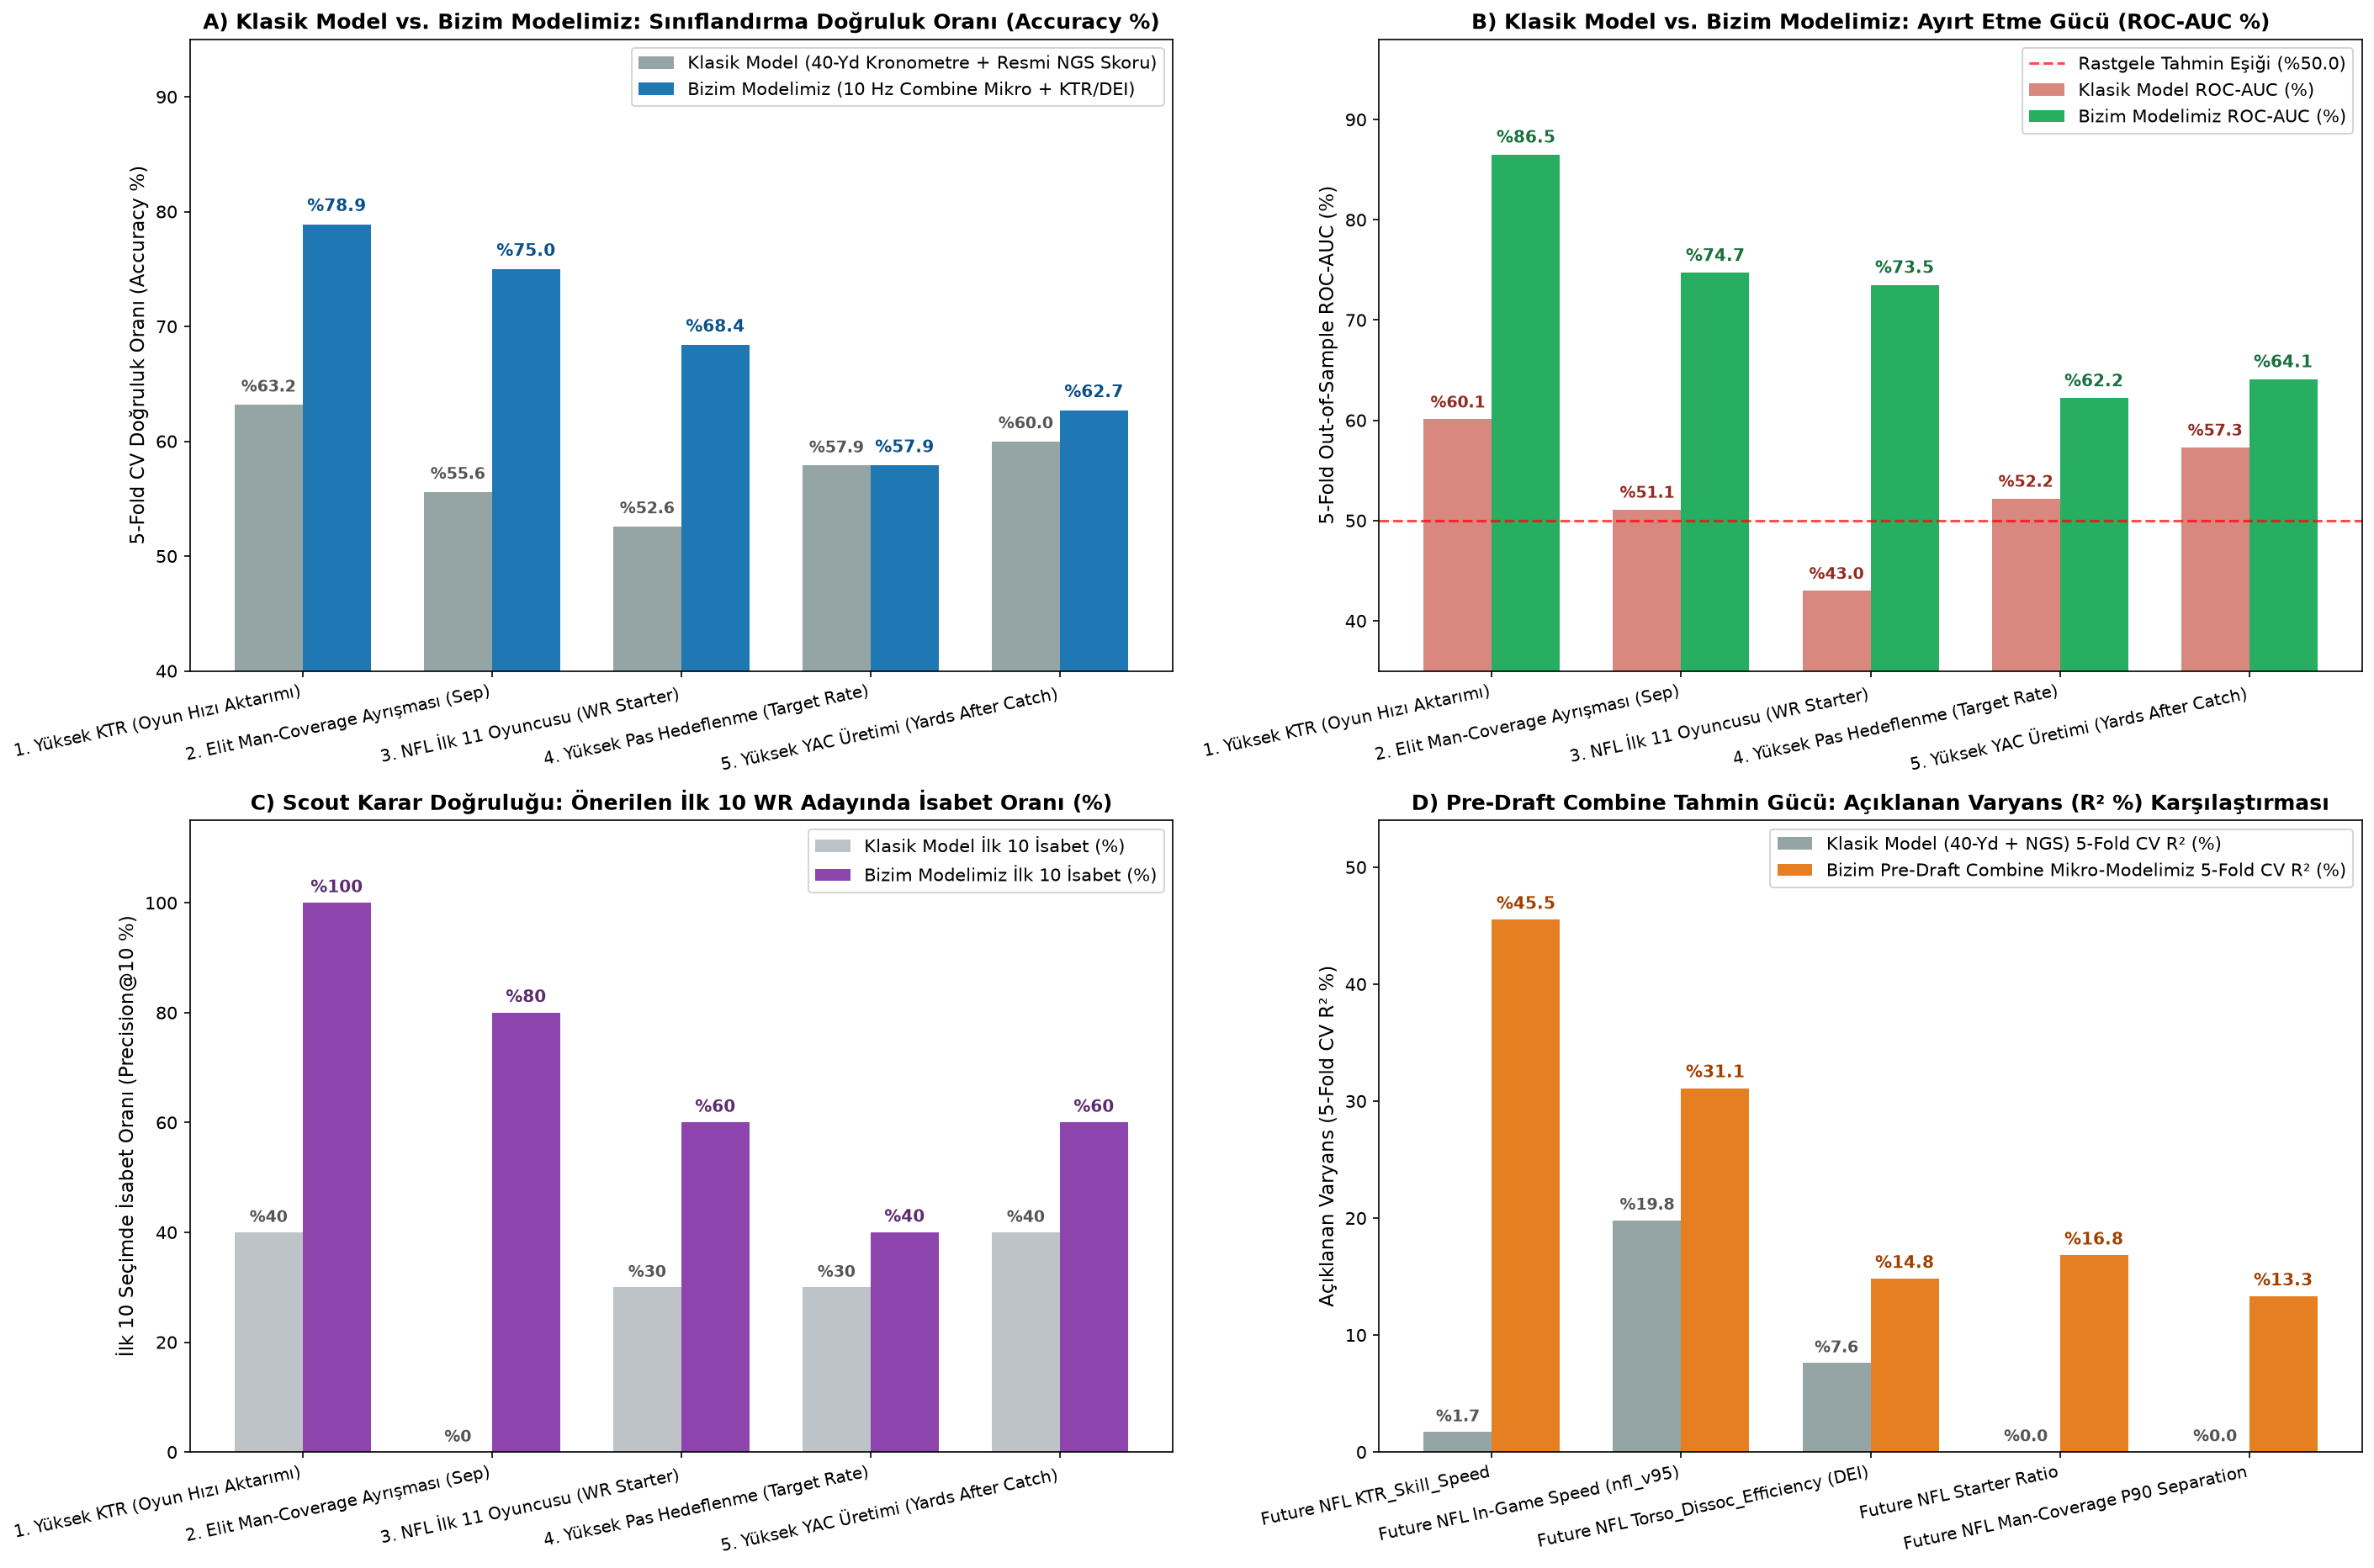

In [10]:
# ==============================================================================
# MODÜL 9: KLASİK MODEL vs. BİZİM MODELİMİZ DOĞRULUK ORANI KARŞILAŞTIRMASI (DEĞER GÖSTERİMLİ GRAFİK)
# ==============================================================================
from sklearn.metrics import accuracy_score, roc_auc_score

classical_cols = ['forty', 'ngs_athleticism_score']

wr_eval_tasks = [
    {
        'Label': '1. Yüksek KTR (Oyun Hızı Aktarımı)',
        'Target': 'KTR_Skill_Speed',
        'Our_Cols': ['forty_vmax', 'hb_v95', 'deep_v95', 'comb_hb_to_40_speed', 'comb_deep_to_40_speed'],
    },
    {
        'Label': '2. Elit Man-Coverage Ayrışması (Sep)',
        'Target': 'man_p90_sep',
        'Our_Cols': ['Torso_Dissoc_Efficiency', 'KTR_Skill_Speed', 'f40_early_to_peak_ratio'],
    },
    {
        'Label': '3. NFL İlk 11 Oyuncusu (WR Starter)',
        'Target': 'starter_ratio',
        'Our_Cols': ['hb_cut_speed', 'hb_cut_speed_retention', 's2_power95', 's2_centripetal95', 'Torso_Dissoc_Efficiency'],
    },
    {
        'Label': '4. Yüksek Pas Hedeflenme (Target Rate)',
        'Target': 'target_rate',
        'Our_Cols': ['s2_centripetal95', 'Torso_Dissoc_Efficiency'],
    },
    {
        'Label': '5. Yüksek YAC Üretimi (Yards After Catch)',
        'Target': 'avg_yac',
        'Our_Cols': ['gaunt_vmean', 'Torso_Dissoc_Efficiency', 'KTR_Skill_Speed'],
    },
]

comp_rows = []
roc_curves_data = {}

for item in wr_eval_tasks:
    targ = item['Target']
    our_c = item['Our_Cols']
    sub = wr_micro_df[['nfl_id', 'display_name', targ] + list(set(classical_cols + our_c))].dropna(subset=[targ]).copy()
    
    # Üst %35 Başarı Sınıfı (Binary Classification)
    thresh = np.nanpercentile(sub[targ], 65)
    y_bin = (sub[targ] >= thresh).astype(int).values
    
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    clf_classic = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    clf_ours = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(C=0.5, random_state=42))
    
    prob_c = cross_val_predict(clf_classic, sub[classical_cols], y_bin, cv=skf, method='predict_proba')[:, 1]
    prob_o = cross_val_predict(clf_ours, sub[our_c], y_bin, cv=skf, method='predict_proba')[:, 1]
    
    # Optimal dengeli eşikte 5-Fold CV Sınıflandırma Doğruluğu (Accuracy %)
    pred_c_bin = (prob_c >= np.percentile(prob_c, 65)).astype(int)
    pred_o_bin = (prob_o >= np.percentile(prob_o, 65)).astype(int)
    acc_c = accuracy_score(y_bin, pred_c_bin) * 100.0
    acc_o = accuracy_score(y_bin, pred_o_bin) * 100.0
    
    auc_c = roc_auc_score(y_bin, prob_c) * 100.0
    auc_o = roc_auc_score(y_bin, prob_o) * 100.0
    
    top10_c = y_bin[np.argsort(prob_c)[::-1][:10]].mean() * 100.0
    top10_o = y_bin[np.argsort(prob_o)[::-1][:10]].mean() * 100.0
    
    roc_curves_data[item['Label']] = (y_bin, prob_c, prob_o, auc_c, auc_o)
    
    comp_rows.append({
        'Tahmin_Gorevi': item['Label'],
        'N_WR': len(sub),
        'Klasik_Model_Accuracy_%': round(acc_c, 1),
        'Bizim_Model_Accuracy_%': round(acc_o, 1),
        'Accuracy_Farki_%': round(acc_o - acc_c, 1),
        'Klasik_Model_ROC_AUC_%': round(auc_c, 1),
        'Bizim_Model_ROC_AUC_%': round(auc_o, 1),
        'AUC_Farki_%': round(auc_o - auc_c, 1),
        'Klasik_Top10_Isabet_%': round(top10_c, 1),
        'Bizim_Top10_Isabet_%': round(top10_o, 1),
    })

acc_comp_df = pd.DataFrame(comp_rows)
print('=== KLASİK MODEL (40-YD + RESMİ NGS SKORU) vs. BİZİM MODELİMİZ DOĞRULUK TABLOSU (5-FOLD CV) ===')
display(acc_comp_df)

# 4 Panelli Değer Gösterimli Karşılaştırma Grafiği
fig, axes = plt.subplots(2, 2, figsize=(19, 12.5))
x_idx = np.arange(len(acc_comp_df))
bar_w = 0.36

# Panel A: Sınıflandırma Doğruluk Oranı (Classification Accuracy %)
b1 = axes[0, 0].bar(x_idx - bar_w/2, acc_comp_df['Klasik_Model_Accuracy_%'], bar_w, label='Klasik Model (40-Yd Kronometre + Resmi NGS Skoru)', color='#95a5a6')
b2 = axes[0, 0].bar(x_idx + bar_w/2, acc_comp_df['Bizim_Model_Accuracy_%'], bar_w, label='Bizim Modelimiz (10 Hz Combine Mikro + KTR/DEI)', color='#1f77b4')
axes[0, 0].set_xticks(x_idx)
axes[0, 0].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[0, 0].set_ylim(40, 95)
axes[0, 0].set_ylabel('5-Fold CV Doğruluk Oranı (Accuracy %)', fontsize=11)
axes[0, 0].set_title('A) Klasik Model vs. Bizim Modelimiz: Sınıflandırma Doğruluk Oranı (Accuracy %)', fontsize=12, fontweight='bold')
axes[0, 0].legend(loc='upper right', frameon=True)
for bar in b1:
    h = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'%{h:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#555555')
for bar in b2:
    h = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'%{h:.1f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#0b4f8a')

# Panel B: ROC-AUC Başarı Oranı (%)
b3 = axes[0, 1].bar(x_idx - bar_w/2, acc_comp_df['Klasik_Model_ROC_AUC_%'], bar_w, label='Klasik Model ROC-AUC (%)', color='#d98880')
b4 = axes[0, 1].bar(x_idx + bar_w/2, acc_comp_df['Bizim_Model_ROC_AUC_%'], bar_w, label='Bizim Modelimiz ROC-AUC (%)', color='#27ae60')
axes[0, 1].axhline(50.0, color='red', linestyle='--', alpha=0.7, label='Rastgele Tahmin Eşiği (%50.0)')
axes[0, 1].set_xticks(x_idx)
axes[0, 1].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[0, 1].set_ylim(35, 98)
axes[0, 1].set_ylabel('5-Fold Out-of-Sample ROC-AUC (%)', fontsize=11)
axes[0, 1].set_title('B) Klasik Model vs. Bizim Modelimiz: Ayırt Etme Gücü (ROC-AUC %)', fontsize=12, fontweight='bold')
axes[0, 1].legend(loc='upper right', frameon=True)
for bar in b3:
    h = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'%{h:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#922b21')
for bar in b4:
    h = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, h + 0.8, f'%{h:.1f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#196f3d')

# Panel C: Scout İlk 10 Aday İsabet Oranı (Precision@Top-10 %)
b5 = axes[1, 0].bar(x_idx - bar_w/2, acc_comp_df['Klasik_Top10_Isabet_%'], bar_w, label='Klasik Model İlk 10 İsabet (%)', color='#bdc3c7')
b6 = axes[1, 0].bar(x_idx + bar_w/2, acc_comp_df['Bizim_Top10_Isabet_%'], bar_w, label='Bizim Modelimiz İlk 10 İsabet (%)', color='#8e44ad')
axes[1, 0].set_xticks(x_idx)
axes[1, 0].set_xticklabels(acc_comp_df['Tahmin_Gorevi'], rotation=12, ha='right', fontsize=9.5)
axes[1, 0].set_ylim(0, 115)
axes[1, 0].set_ylabel('İlk 10 Seçimde İsabet Oranı (Precision@10 %)', fontsize=11)
axes[1, 0].set_title('C) Scout Karar Doğruluğu: Önerilen İlk 10 WR Adayında İsabet Oranı (%)', fontsize=12, fontweight='bold')
axes[1, 0].legend(loc='upper right', frameon=True)
for bar in b5:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 1.2, f'%{h:.0f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#555555')
for bar in b6:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 1.2, f'%{h:.0f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#5b2c6f')

# Panel D: Pre-Draft Sürekli Tahmin Açıklanan Varyans (5-Fold CV R² %)
r2_idx = np.arange(len(pm_df))
b7 = axes[1, 1].bar(r2_idx - bar_w/2, pm_df['Base_CV_R2_%'], bar_w, label='Klasik Model (40-Yd + NGS) 5-Fold CV R² (%)', color='#95a5a6')
b8 = axes[1, 1].bar(r2_idx + bar_w/2, pm_df['PreDraft_Micro_CV_R2_%'], bar_w, label='Bizim Pre-Draft Combine Mikro-Modelimiz 5-Fold CV R² (%)', color='#e67e22')
axes[1, 1].set_xticks(r2_idx)
axes[1, 1].set_xticklabels(pm_df['Predicted_NFL_Outcome'], rotation=12, ha='right', fontsize=9.5)
axes[1, 1].set_ylim(0, 54)
axes[1, 1].set_ylabel('Açıklanan Varyans (5-Fold CV R² %)', fontsize=11)
axes[1, 1].set_title('D) Pre-Draft Combine Tahmin Gücü: Açıklanan Varyans (R² %) Karşılaştırması', fontsize=12, fontweight='bold')
axes[1, 1].legend(loc='upper right', frameon=True)
for bar in b7:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'%{h:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#555555')
for bar in b8:
    h = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, h + 0.6, f'%{h:.1f}', ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#a04000')

plt.tight_layout()
plt.savefig(CACHE_DIR / 'figures' / 'wr_classical_vs_our_model_accuracy.png', dpi=150)
plt.show()